In [1]:
from pathlib import Path
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import Markdown, display
from pmdarima.arima import auto_arima
from sklearn.metrics import mean_squared_error, silhouette_score
from sklearn.preprocessing import StandardScaler
from sktime.forecasting.base import ForecastingHorizon
from sktime.forecasting.naive import NaiveForecaster
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from sklearn.cluster import KMeans

In [2]:
# Общие функции оформления результатов используются на всех этапах.
def show_markdown(*values, sep=' ', end='\n'):
    """Отображаем текст как Markdown в выводе ячейки."""
    text = sep.join(str(value) for value in values)
    if text.strip():
        display(Markdown(text))


def show_markdown_table(frame, title, include_index=False, digits=3):
    """Выводим полную Markdown-таблицу без зависимости tabulate."""
    if isinstance(frame, pd.Series):
        frame = frame.to_frame()
    table = frame.reset_index() if include_index else frame

    def format_cell(value):
        if value is None or value is pd.NA or (np.isscalar(value) and pd.isna(value)):
            return '—'
        if isinstance(value, (float, np.floating)):
            value = f'{value:.{digits}f}'
        return str(value).replace('\\', '\\\\').replace('|', '&#124;').replace('\n', '<br>')

    header = '| ' + ' | '.join(format_cell(column) for column in table.columns) + ' |'
    separator = '| ' + ' | '.join('---' for _ in table.columns) + ' |'
    rows = [
        '| ' + ' | '.join(format_cell(value) for value in row) + ' |'
        for row in table.itertuples(index=False, name=None)
    ]
    display(Markdown(f'### {title}\n\n' + '\n'.join([header, separator, *rows])))


def show_dataframe_info(frame):
    """Сохраняем полную диагностику pandas в Markdown-блоке и показываем начало данных."""
    buffer = io.StringIO()
    frame.info(buf=buffer)
    show_markdown('### Информация о данных\n\n```text\n' + buffer.getvalue() + '```')
    show_markdown_table(frame.head(), 'Первые строки данных')


## Этап 1. Загрузка и подготовка данных

### Этапы выполнения
1. Загружаем CSV-файл в pandas.
2. Выводим базовую информацию о датасете: количество строк/столбцов, названия колонок, типы данных (`df.info()`, `df.head()`).
3. Преобразуем данные из широкого формата в длинный: одна строка = «регион — год», значение показателя — в отдельной колонке. Использовать `pd.melt`.
4. Приводим годовые значения к числовому типу: заменить спецсимволы (например, `…`) на пропуски (`NaN`), преобразовать колонки с годами в `float`.
5. Отфильтруем регионы: оставить только те, у которых есть данные за весь период 2000–2023 (без пропусков внутри ряда). Длинные начальные пропуски не восстанавливать.


In [3]:
# Загружаем данные, убираем лишний столбец, приводим пропуски к формату NaN

datapath = Path('data')
datapath.mkdir(exist_ok=True)
file_name = 'rsdocs_1491005410458_wide_appendix_2025.csv'
df = pd.read_csv(datapath / file_name,
                encoding='utf-8',
                dtype=str,
                na_values=['…', ''])

df = df.drop(columns='Unnamed: 28')


In [4]:
show_dataframe_info(df)


### Информация о данных

```text
<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   region_name     96 non-null     str  
 1   region_code     94 non-null     str  
 2   indicator_name  96 non-null     str  
 3   measure_unit    96 non-null     str  
 4   2000            88 non-null     str  
 5   2001            88 non-null     str  
 6   2002            88 non-null     str  
 7   2003            91 non-null     str  
 8   2004            91 non-null     str  
 9   2005            92 non-null     str  
 10  2006            92 non-null     str  
 11  2007            92 non-null     str  
 12  2008            92 non-null     str  
 13  2009            92 non-null     str  
 14  2010            92 non-null     str  
 15  2011            94 non-null     str  
 16  2012            94 non-null     str  
 17  2013            94 non-null     str  
 18  2014            96 non-null     str  
 19  2015            96 non-null     str  
 20  2016            96 non-null     str  
 21  2017            96 non-null     str  
 22  2018            96 non-null     str  
 23  2019            96 non-null     str  
 24  2020            96 non-null     str  
 25  2021            96 non-null     str  
 26  2022            96 non-null     str  
 27  2023            96 non-null     str  
dtypes: str(28)
memory usage: 21.1 KB
```

### Первые строки данных

| region_name | region_code | indicator_name | measure_unit | 2000 | 2001 | 2002 | 2003 | 2004 | 2005 | 2006 | 2007 | 2008 | 2009 | 2010 | 2011 | 2012 | 2013 | 2014 | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 | 2022 | 2023 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего | — | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 24964,9 | 33073,8 | 42325,5 | 50809 | 63177,6 | 79943,6 | 99969 | 124846,2 | 156161 | 164847,7 | 183266 | 214113 | 239135,9 | 262359,5 | 279922,2 | 296330,1 | 335157,9 | 352032,4 | 378631,5 | 396539,7 | 409455,2 | 482117,7 | 537330,3 | 605276,8 |
| Центральный федеральный округ | 30 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 37398,9 | 48743,1 | 60043,2 | 71997,2 | 86784,2 | 106512,6 | 129801,3 | 159400,6 | 196202,6 | 207213,9 | 231720,5 | 272574 | 302078,7 | 326737,5 | 357669,5 | 371888,6 | 428461,6 | 449367,4 | 483617,8 | 504322,7 | 522640,3 | 622652,4 | 670468,1 | 745978,7 |
| Белгородская область | 14000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 19420,9 | 22799,1 | 26386,5 | 31254 | 39422,8 | 48000,4 | 64017,4 | 83720,9 | 110581,7 | 121935,4 | 138080,2 | 162871,1 | 187390,1 | 212122,3 | 234785,7 | 252179,1 | 299984 | 321377,9 | 343531,1 | 362467 | 386681 | 432635,6 | 488454 | 514718 |
| Брянская область | 15000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 13394,1 | 18433,1 | 25521 | 31086,7 | 40350,3 | 49910,6 | 62672 | 80660,2 | 104323,3 | 115033,1 | 133410 | 157478 | 174784,3 | 196372,9 | 219469,5 | 241902,5 | 274857,8 | 297109,4 | 323017,1 | 349656,3 | 355519,2 | 406107 | 448468,7 | 489083,4 |
| Владимирская область | 17000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 13034,5 | 16869,4 | 21268,7 | 27059,7 | 33793,5 | 41854,3 | 55340,6 | 74623,9 | 95423,3 | 102215,7 | 118139,8 | 141186 | 167421,9 | 185962,3 | 205329,2 | 220159,8 | 257385,6 | 270483,3 | 290474,2 | 310050,9 | 321180,3 | 360929,3 | 414359,9 | 459450,1 |

In [5]:
# Удалим общую информацию и строки, где по заданию указаны пропуски
rows_to_drop = [
    'Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего',
    'Архангельская область без автономного округа',
    'Тюменская область без автономных округов',
    'Республика Крым',
    'г. Севастополь',
]

df = df.loc[~df['region_name'].isin(rows_to_drop)]
df = df.loc[~df['region_name'].str.contains('федераль')]

show_dataframe_info(df)


### Информация о данных

```text
<class 'pandas.DataFrame'>
Index: 83 entries, 2 to 95
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   region_name     83 non-null     str  
 1   region_code     82 non-null     str  
 2   indicator_name  83 non-null     str  
 3   measure_unit    83 non-null     str  
 4   2000            79 non-null     str  
 5   2001            79 non-null     str  
 6   2002            79 non-null     str  
 7   2003            82 non-null     str  
 8   2004            82 non-null     str  
 9   2005            83 non-null     str  
 10  2006            83 non-null     str  
 11  2007            83 non-null     str  
 12  2008            83 non-null     str  
 13  2009            83 non-null     str  
 14  2010            83 non-null     str  
 15  2011            83 non-null     str  
 16  2012            83 non-null     str  
 17  2013            83 non-null     str  
 18  2014            83 non-null     str  
 19  2015            83 non-null     str  
 20  2016            83 non-null     str  
 21  2017            83 non-null     str  
 22  2018            83 non-null     str  
 23  2019            83 non-null     str  
 24  2020            83 non-null     str  
 25  2021            83 non-null     str  
 26  2022            83 non-null     str  
 27  2023            83 non-null     str  
dtypes: str(28)
memory usage: 18.8 KB
```

### Первые строки данных

| region_name | region_code | indicator_name | measure_unit | 2000 | 2001 | 2002 | 2003 | 2004 | 2005 | 2006 | 2007 | 2008 | 2009 | 2010 | 2011 | 2012 | 2013 | 2014 | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 | 2021 | 2022 | 2023 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Белгородская область | 14000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 19420,9 | 22799,1 | 26386,5 | 31254 | 39422,8 | 48000,4 | 64017,4 | 83720,9 | 110581,7 | 121935,4 | 138080,2 | 162871,1 | 187390,1 | 212122,3 | 234785,7 | 252179,1 | 299984 | 321377,9 | 343531,1 | 362467 | 386681 | 432635,6 | 488454 | 514718 |
| Брянская область | 15000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 13394,1 | 18433,1 | 25521 | 31086,7 | 40350,3 | 49910,6 | 62672 | 80660,2 | 104323,3 | 115033,1 | 133410 | 157478 | 174784,3 | 196372,9 | 219469,5 | 241902,5 | 274857,8 | 297109,4 | 323017,1 | 349656,3 | 355519,2 | 406107 | 448468,7 | 489083,4 |
| Владимирская область | 17000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 13034,5 | 16869,4 | 21268,7 | 27059,7 | 33793,5 | 41854,3 | 55340,6 | 74623,9 | 95423,3 | 102215,7 | 118139,8 | 141186 | 167421,9 | 185962,3 | 205329,2 | 220159,8 | 257385,6 | 270483,3 | 290474,2 | 310050,9 | 321180,3 | 360929,3 | 414359,9 | 459450,1 |
| Воронежская область | 20000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 17152,6 | 23845,1 | 29642 | 34611,6 | 43979,1 | 55782,6 | 66872,6 | 82514,9 | 102949,2 | 116517,8 | 141122,9 | 183968 | 217083,8 | 246462,4 | 275262 | 300850 | 321220,1 | 338065,6 | 363825,9 | 359513,3 | 365099,5 | 433703,1 | 483900,8 | 514348,3 |
| Ивановская область | 24000000000 | Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей) | в текущих рыночных ценах; рублей | 11838,1 | 15897,7 | 19111,9 | 24070,7 | 30903,8 | 38875,4 | 50755,3 | 66363,3 | 88962,8 | 94725,2 | 110802,5 | 135649,6 | 165147,1 | 181753,9 | 206067,6 | 216507,5 | 240666,6 | 252948,8 | 278758,6 | 303291,7 | 315327,1 | 366999,9 | 427538,8 | 462492 |

In [6]:
# Применяем melt и преобразуем данные из широкого формата в длинный: одна строка = «регион — год», значение показателя — в отдельной колонке. Использовать `pd.melt`.

df_long = pd.melt(
    df,
    id_vars= ['region_name', 'region_code', 'indicator_name', 'measure_unit'],  # колонки, которые нужно сохранить
    value_vars=[str(year) for year in range(2000, 2024)],  # только годовые колонки
    var_name='year',  # имя для новой колонки с названиями (по умолчанию 'variable')
    value_name="value",  # имя для новой колонки со значениями (по умолчанию 'value')
    ignore_index=True,  # сбрасывать ли индекс (по умолчанию True)
)
df_long = df_long[['region_name', 'year','value']]
df_long['value'] = pd.to_numeric(
    df_long['value'].str.replace(',', '.', regex=False), errors='coerce'
)
# Оставляем целые ряды: удаление отдельных пропусков искажает годовую динамику.
incomplete = df_long.groupby('region_name')['value'].apply(lambda s: s.isna().any())
excluded_regions = incomplete[incomplete].index.tolist()
show_markdown('Исключены регионы с неполными рядами:', excluded_regions)
df_long = df_long.loc[~df_long['region_name'].isin(excluded_regions)].copy()
df_long = df_long.sort_values(['region_name','year']).reset_index(drop=True)
df_long['year'] = df_long['year'].astype(int)
show_markdown(f'Число регионов в полными рядами {len(df_long['region_name'].unique())}')


Исключены регионы с неполными рядами: ['Ненецкий автономный округ', 'Ханты-Мансийский автономный округ – Югра', 'Чеченская Республика', 'Ямало-Ненецкий автономный округ']

Число регионов в полными рядами 79

## Выводы по этапу 1
1. Число регионов с полными рядами, без дубликатов 79. Удаленные регионы 'Ненецкий автономный округ', 'Ханты-Мансийский автономный округ – Югра', 'Чеченская Республика', 'Ямало-Ненецкий автономный округ'
2. Для каждого региона построен отдельный временной ряд (индекс — год, значения — потребление).

## Этап 2. Кластерный анализ регионов

### Задачи
1. Для каждого оставшегося региона извлекаем признаки на основе временного ряда. Используем следующие признаки:
   - среднее значение за период (уровень потребления);
   - коэффициент вариации (std / mean) — относительная волатильность;
   - средний годовой темп роста (или медианный темп роста);
   - относительное изменение за весь период (значение 2023 / значение 2000);
   - максимальное годовое падение (наибольшее отрицательное изменение год к году);
   - доля лет с отрицательной динамикой (число лет, когда показатель снизился относительно предыдущего года).
2. Для кластеризации стандартизируем признаки через `StandardScaler` из scikit-learn .
3. Проводим кластеризацию с помощью Kmeans.
4. Рассмотрим варианты с 2, 3 и 4 кластерами. Для каждого варианта считаем `silhouette_score`.


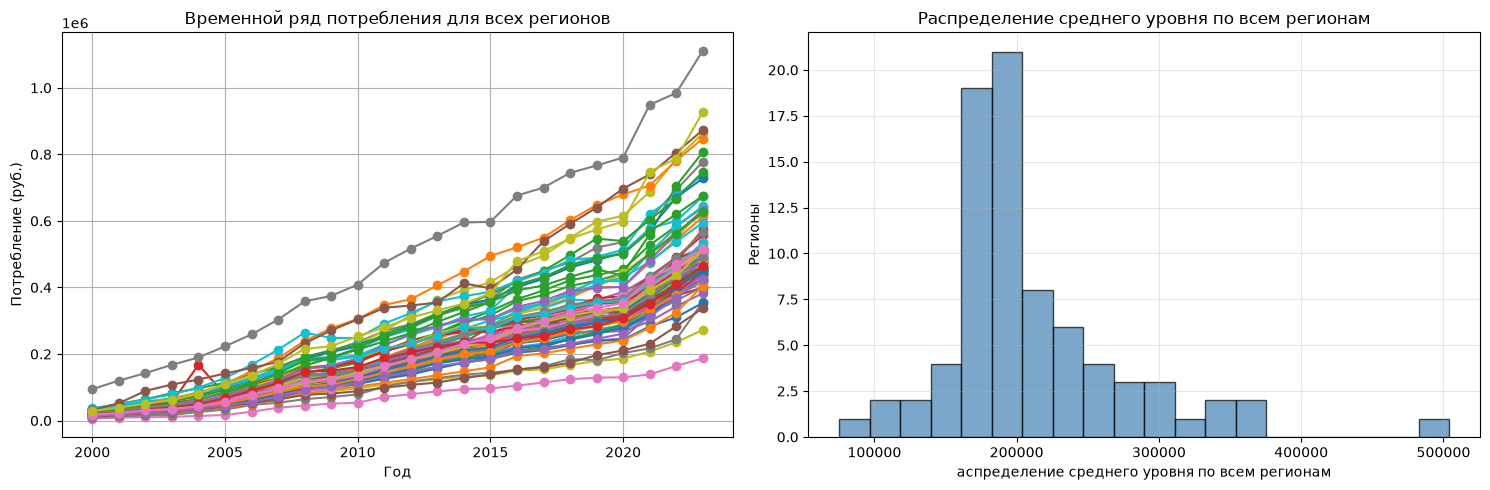

In [7]:
# Создаем отдельные временные ряды
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

time_series = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()


for region in time_series.columns:
    # Исходный ряд
    axes[0].plot(time_series[region], marker='o')
axes[0].set_title(f'Временной ряд потребления для всех регионов')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Потребление (руб.)')
axes[0].grid(True)

# справа - распределение среднего уровня по странам
mean_levels = [time_series[region].mean() for region in time_series.columns]
axes[1].hist(mean_levels, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
axes[1].set_title('Распределение среднего уровня по всем регионам')
axes[1].set_xlabel('аспределение среднего уровня по всем регионам')
axes[1].set_ylabel('Регионы')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
# Рассчитываем показатели для каждого региона
def region_stats_make(df_long):
    # Создаем временной ряд для каждого региона
    time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)
    # Рассчитываем показатели для каждого региона
    region_stats = []
    for region in time_series.columns:
        series = time_series[region].dropna()

        # Среднее значение
        mean_value = series.mean()

        # Коэффициент вариации
        variation_coef = series.std() / mean_value

        # Среднегодовой прирост : степень обратна числу лет между наблюдениями.
        years = series.index[-1] - series.index[0]
        growth_rate = (series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1

        # Относительное изменение
        relative_change = series.iloc[-1] / series.iloc[0]

        # Максимальное падение
        yearly_changes = series.pct_change().dropna()
        max_drop = yearly_changes.min()

        # Доля лет с отрицательной динамикой
        negative_years = (yearly_changes < 0).sum() / len(yearly_changes)

        region_stats.append({
            'region_name': region,
            'Среднее значение': mean_value,
            'Коэфф. вариации': variation_coef,
            'Среднегодовой темп роста': growth_rate,
            'Относит. изменение': relative_change,
            'Макс. падение': max_drop,
            'Доля отрицат. динамики': negative_years
        })
    region_stats = pd.DataFrame(region_stats)
    # Форматируем результаты
    region_stats['Коэфф. вариации'] = region_stats['Коэфф. вариации'] * 100
    region_stats['Среднегодовой темп роста'] = region_stats['Среднегодовой темп роста'] * 100
    region_stats['Макс. падение'] = region_stats['Макс. падение'] * 100

    return region_stats

# Выводим результаты
region_stats = region_stats_make(df_long)
show_markdown_table(region_stats, 'Признаки регионов')


### Признаки регионов

| region_name | Среднее значение | Коэфф. вариации | Среднегодовой темп роста | Относит. изменение | Макс. падение | Доля отрицат. динамики |
| --- | --- | --- | --- | --- | --- | --- |
| Алтайский край | 166038.221 | 69.386 | 15.312 | 26.489 | -1.030 | 0.043 |
| Амурская область | 231900.292 | 78.214 | 15.875 | 29.630 | 3.509 | 0.000 |
| Архангельская область | 253850.283 | 74.249 | 16.107 | 31.026 | 3.716 | 0.000 |
| Астраханская область | 180520.654 | 66.050 | 14.702 | 23.450 | 0.862 | 0.000 |
| Белгородская область | 204367.342 | 77.001 | 15.314 | 26.503 | 5.377 | 0.000 |
| Брянская область | 192025.854 | 76.497 | 16.932 | 36.515 | 1.677 | 0.000 |
| Владимирская область | 175166.508 | 77.107 | 16.753 | 35.249 | 3.590 | 0.000 |
| Волгоградская область | 178848.196 | 67.700 | 15.714 | 28.702 | 3.978 | 0.000 |
| Вологодская область | 178159.446 | 72.352 | 14.475 | 22.404 | 0.043 | 0.000 |
| Воронежская область | 213262.217 | 74.399 | 15.935 | 29.987 | -1.185 | 0.043 |
| Еврейская автономная область | 187223.842 | 68.736 | 15.875 | 29.632 | 2.933 | 0.000 |
| Забайкальский край | 180943.742 | 68.278 | 16.089 | 30.918 | -0.712 | 0.043 |
| Ивановская область | 171060.663 | 79.757 | 17.276 | 39.068 | 3.968 | 0.000 |
| Иркутская область | 186187.921 | 70.957 | 14.181 | 21.117 | 1.306 | 0.000 |
| Кабардино-Балкарская Республика | 154928.238 | 77.371 | 16.085 | 30.892 | 2.171 | 0.000 |
| Калинингpадская область | 201188.858 | 72.032 | 14.898 | 24.388 | 1.546 | 0.000 |
| Калужская область | 202046.875 | 70.399 | 16.189 | 31.533 | 1.632 | 0.000 |
| Камчатский край | 305570.275 | 70.867 | 14.318 | 21.710 | 3.136 | 0.000 |
| Карачаево-Черкесская Республика | 113121.637 | 63.519 | 13.907 | 19.984 | 2.006 | 0.000 |
| Кемеровская область | 177866.738 | 63.460 | 14.534 | 22.671 | -9.362 | 0.043 |
| Кировская область | 173806.121 | 74.612 | 15.583 | 27.963 | 5.333 | 0.000 |
| Костромская область | 176242.696 | 76.895 | 15.677 | 28.487 | 4.621 | 0.000 |
| Краснодарский край | 263403.688 | 81.900 | 17.538 | 41.123 | 3.789 | 0.000 |
| Красноярский край | 232202.529 | 63.187 | 13.807 | 19.582 | -53.292 | 0.043 |
| Курганская область | 160871.421 | 66.140 | 15.748 | 28.896 | -3.895 | 0.043 |
| Курская область | 190928.508 | 73.677 | 16.015 | 30.467 | 3.114 | 0.000 |
| Ленинградская область | 207787.196 | 73.787 | 16.553 | 33.886 | 0.225 | 0.000 |
| Липецкая область | 208141.954 | 72.870 | 15.194 | 25.878 | 1.130 | 0.000 |
| Магаданская область | 334792.000 | 75.172 | 15.672 | 28.463 | 2.964 | 0.000 |
| Московская область | 288251.079 | 74.417 | 16.906 | 36.330 | 1.074 | 0.000 |
| Мурманская область | 294447.221 | 69.353 | 14.608 | 23.009 | 4.285 | 0.000 |
| Нижегородская область | 231224.450 | 75.514 | 16.595 | 34.171 | 0.091 | 0.000 |
| Новгородская область | 199141.558 | 68.859 | 14.722 | 23.544 | 0.200 | 0.000 |
| Новосибирская область | 220986.212 | 65.789 | 15.001 | 24.896 | 0.306 | 0.000 |
| Омская область | 196246.729 | 69.789 | 16.182 | 31.491 | -0.197 | 0.043 |
| Оренбургская область | 178194.083 | 73.342 | 15.843 | 29.446 | 2.416 | 0.000 |
| Орловская область | 180074.746 | 75.263 | 15.620 | 28.170 | 4.821 | 0.000 |
| Пензенская область | 164584.396 | 70.617 | 15.746 | 28.883 | 1.605 | 0.000 |
| Пермский край | 221578.492 | 63.714 | 14.199 | 21.195 | -1.479 | 0.043 |
| Приморский край | 236737.158 | 77.121 | 16.536 | 33.773 | -0.388 | 0.043 |
| Псковская область | 185284.188 | 73.351 | 15.960 | 30.136 | 6.686 | 0.000 |
| Республика Адыгея | 186454.292 | 80.887 | 16.496 | 33.505 | 0.021 | 0.000 |
| Республика Алтай | 163383.517 | 75.118 | 16.942 | 36.584 | 4.930 | 0.000 |
| Республика Башкортостан | 217936.104 | 65.316 | 15.092 | 25.353 | 0.896 | 0.000 |
| Республика Бурятия | 193394.971 | 70.398 | 15.314 | 26.504 | 2.230 | 0.000 |
| Республика Дагестан | 184493.342 | 70.834 | 18.674 | 51.310 | -4.012 | 0.087 |
| Республика Ингушетия | 75110.613 | 71.610 | 16.088 | 30.909 | 0.659 | 0.000 |
| Республика Калмыкия | 114910.296 | 76.386 | 17.171 | 38.271 | -1.742 | 0.043 |
| Республика Карелия | 234689.721 | 76.032 | 15.788 | 29.127 | 5.039 | 0.000 |
| Республика Коми | 254857.196 | 63.402 | 14.288 | 21.577 | 0.131 | 0.000 |
| Республика Марий Эл | 142942.121 | 70.199 | 15.292 | 26.386 | 1.507 | 0.000 |
| Республика Мордовия | 137868.238 | 76.617 | 15.745 | 28.879 | 4.220 | 0.000 |
| Республика Саха (Якутия) | 309057.267 | 67.807 | 14.118 | 20.853 | -1.367 | 0.043 |
| Республика Северная Осетия – Алания | 174250.700 | 73.208 | 15.645 | 28.309 | 1.880 | 0.000 |
| Республика Татарстан | 247015.658 | 71.135 | 16.214 | 31.690 | 0.274 | 0.000 |
| Республика Тыва | 118712.554 | 73.166 | 16.094 | 30.947 | 4.379 | 0.000 |
| Республика Хакасия | 169945.346 | 73.260 | 15.115 | 25.470 | 4.049 | 0.000 |
| Ростовская область | 218896.179 | 71.373 | 15.843 | 29.447 | -2.038 | 0.043 |
| Рязанская область | 184613.829 | 75.550 | 16.286 | 32.145 | 6.401 | 0.000 |
| Самарская область | 231321.304 | 59.389 | 12.506 | 15.032 | -2.216 | 0.043 |
| Саратовская область | 160952.100 | 71.716 | 15.012 | 24.949 | 3.812 | 0.000 |
| Сахалинская область | 371807.683 | 68.736 | 16.615 | 34.303 | 3.919 | 0.000 |
| Свердловская область | 270959.783 | 67.053 | 15.710 | 28.676 | -4.228 | 0.043 |
| Смоленская область | 184232.663 | 69.008 | 14.452 | 22.300 | 3.000 | 0.000 |
| Ставропольский край | 184669.137 | 66.918 | 15.062 | 25.201 | -1.522 | 0.043 |
| Тамбовская область | 185619.163 | 71.635 | 15.082 | 25.301 | -0.742 | 0.043 |
| Тверская область | 192903.254 | 73.356 | 16.349 | 32.551 | 2.564 | 0.000 |
| Томская область | 191444.667 | 67.762 | 14.579 | 22.880 | 1.417 | 0.000 |
| Тульская область | 192434.017 | 74.964 | 16.763 | 35.320 | 2.328 | 0.000 |
| Тюменская область | 313281.888 | 59.682 | 13.539 | 18.550 | -6.018 | 0.043 |
| Удмуртская Республика | 175615.179 | 72.982 | 15.233 | 26.077 | 3.767 | 0.000 |
| Ульяновская область | 168056.167 | 70.957 | 15.368 | 26.788 | 4.037 | 0.000 |
| Хабаровский край | 282873.754 | 70.313 | 15.168 | 25.739 | 2.689 | 0.000 |
| Челябинская область | 190116.308 | 65.092 | 15.072 | 25.251 | -0.310 | 0.043 |
| Чувашская Республика | 152949.233 | 74.807 | 16.109 | 31.038 | 2.255 | 0.000 |
| Чукотский автономный округ | 369809.888 | 67.667 | 15.669 | 28.446 | -3.612 | 0.043 |
| Ярославская область | 199438.087 | 74.677 | 15.867 | 29.587 | 4.444 | 0.000 |
| г. Москва | 504230.938 | 58.184 | 11.316 | 11.772 | 0.281 | 0.000 |
| г. Санкт-Петербург | 341235.579 | 74.971 | 16.253 | 31.938 | 3.998 | 0.000 |

In [9]:
# Метки кластеров и названия регионов не попадают в обучение.
feature_columns = [
    'Среднее значение',
    'Коэфф. вариации',
    'Среднегодовой темп роста',
    'Макс. падение',
    'Доля отрицат. динамики',
]

features = region_stats.set_index('region_name')[feature_columns].copy()
X = StandardScaler().fit_transform(features)

# Сравниваем 2, 3 и 4 кластера.
labels_by_k = {}
comparison = []

for k in [2, 3, 4]:
    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=42,
    )
    labels = model.fit_predict(X)
    labels_by_k[k] = labels

    sizes = pd.Series(labels).value_counts().sort_index()

    comparison.append({
        'k': k,
        'Silhouette': silhouette_score(X, labels),
        'Размеры групп': sizes.to_dict(),
        'Минимальный размер группы': sizes.min(),
    })

comparison_df = pd.DataFrame(comparison)

show_markdown_table(
    comparison_df,
    'Сравнение числа кластеров',
    digits=4,
)

best_k = int(
    comparison_df.loc[comparison_df['Silhouette'].idxmax(), 'k']
)
display(Markdown(
    f'**Наибольший silhouette получен при k={best_k}.**'
))

# Три группы — вариант для содержательного анализа.
chosen_k = 3

clustered = features.copy()
clustered['Кластер'] = labels_by_k[chosen_k]

profiles = clustered.groupby('Кластер')[feature_columns].mean()
profiles.insert(
    0,
    'Число регионов',
    clustered.groupby('Кластер').size(),
)

show_markdown_table(
    profiles,
    'Средние характеристики кластеров',
    include_index=True,
)

for cluster, group in clustered.groupby('Кластер'):
    display(Markdown(
        f'#### Кластер {cluster}: {len(group)} регионов\n\n'
        + ', '.join(group.index)
    ))

### Сравнение числа кластеров

| k | Silhouette | Размеры групп | Минимальный размер группы |
| --- | --- | --- | --- |
| 2 | 0.4099 | {0: 59, 1: 20} | 20 |
| 3 | 0.3993 | {0: 59, 1: 19, 2: 1} | 1 |
| 4 | 0.3493 | {0: 46, 1: 17, 2: 1, 3: 15} | 1 |

**Наибольший silhouette получен при k=2.**

### Средние характеристики кластеров

| Кластер | Число регионов | Среднее значение | Коэфф. вариации | Среднегодовой темп роста | Макс. падение | Доля отрицат. динамики |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 59 | 200429.906 | 73.025 | 15.753 | 2.656 | 0.001 |
| 1 | 19 | 238637.892 | 66.537 | 14.994 | -2.290 | 0.041 |
| 2 | 1 | 232202.529 | 63.187 | 13.807 | -53.292 | 0.043 |

#### Кластер 0: 59 регионов

Амурская область, Архангельская область, Астраханская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Вологодская область, Еврейская автономная область, Ивановская область, Иркутская область, Кабардино-Балкарская Республика, Калинингpадская область, Калужская область, Камчатский край, Карачаево-Черкесская Республика, Кировская область, Костромская область, Краснодарский край, Курская область, Ленинградская область, Липецкая область, Магаданская область, Московская область, Мурманская область, Нижегородская область, Новгородская область, Новосибирская область, Оренбургская область, Орловская область, Пензенская область, Приморский край, Псковская область, Республика Адыгея, Республика Алтай, Республика Башкортостан, Республика Бурятия, Республика Ингушетия, Республика Калмыкия, Республика Карелия, Республика Марий Эл, Республика Мордовия, Республика Северная Осетия – Алания, Республика Татарстан, Республика Тыва, Республика Хакасия, Рязанская область, Саратовская область, Сахалинская область, Смоленская область, Тверская область, Томская область, Тульская область, Удмуртская Республика, Ульяновская область, Хабаровский край, Чувашская Республика, Ярославская область, г. Санкт-Петербург

#### Кластер 1: 19 регионов

Алтайский край, Воронежская область, Забайкальский край, Кемеровская область, Курганская область, Омская область, Пермский край, Республика Дагестан, Республика Коми, Республика Саха (Якутия), Ростовская область, Самарская область, Свердловская область, Ставропольский край, Тамбовская область, Тюменская область, Челябинская область, Чукотский автономный округ, г. Москва

#### Кластер 2: 1 регионов

Красноярский край

## Этап 3. Выбор регионов для детального прогнозирования 
### Задачи
Выбираем 3 региона — по одному из разных кластеров (или 3 репрезентативных региона, если кластеров больше).



In [10]:
clustered

,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Макс. падение,Доля отрицат. динамики,Кластер
region_name,,,,,,
Алтайский край,166038.220833,69.385702,15.311520,-1.029618,0.043478,1
Амурская область,231900.291667,78.213754,15.874638,3.508777,0.000000,0
Архангельская область,253850.283333,74.248898,16.106854,3.716445,0.000000,0
Астраханская область,180520.654167,66.050339,14.702069,0.861605,0.000000,0
Белгородская область,204367.341667,77.000531,15.314152,5.376965,0.000000,0
...,...,...,...,...,...,...
Чувашская Республика,152949.233333,74.806523,16.108748,2.255219,0.000000,0
Чукотский автономный округ,369809.887500,67.666672,15.669343,-3.611779,0.043478,1
Ярославская область,199438.087500,74.676741,15.867348,4.444213,0.000000,0


In [11]:

# Проверяем размеры групп
show_markdown_table(
    clustered['Кластер'].value_counts().sort_index().rename('Число регионов'),
    'Размеры кластеров', include_index=True,
)

region_stats['Кластер'] = clustered['Кластер'].to_numpy()

# Сравниваем характеристики
show_markdown_table(region_stats.groupby('Кластер')[
        ['Среднее значение',
         'Коэфф. вариации',
         'Среднегодовой темп роста',
         'Макс. падение',
         'Доля отрицат. динамики']
    ].mean().round(3), 'Характеристики кластеров', include_index=True)


### Размеры кластеров

| Кластер | Число регионов |
| --- | --- |
| 0 | 59 |
| 1 | 19 |
| 2 | 1 |

### Характеристики кластеров

| Кластер | Среднее значение | Коэфф. вариации | Среднегодовой темп роста | Макс. падение | Доля отрицат. динамики |
| --- | --- | --- | --- | --- | --- |
| 0 | 200429.906 | 73.025 | 15.753 | 2.656 | 0.001 |
| 1 | 238637.892 | 66.537 | 14.994 | -2.290 | 0.041 |
| 2 | 232202.529 | 63.187 | 13.807 | -53.292 | 0.043 |

In [12]:
features = [
    'Среднее значение',
    'Коэфф. вариации',
    'Среднегодовой темп роста',
    'Относит. изменение',
    'Макс. падение',
    'Доля отрицат. динамики'
]

scaled = pd.DataFrame(
    StandardScaler().fit_transform(region_stats[features]),
    index=region_stats.index,
    columns=features
)

regions_list = []

for cluster, group in region_stats.groupby('Кластер', sort=True):
    cluster_features = scaled.loc[group.index]
    center = cluster_features.mean()

    # Квадрат евклидова расстояния до центра кластера.
    distances = cluster_features.sub(center).pow(2).sum(axis=1)
    chosen_idx = distances.idxmin()
    chosen = region_stats.loc[chosen_idx, 'region_name']

    regions_list.append(chosen)
    show_markdown(f'Для кластера {cluster} выбран регион: {chosen}')


Для кластера 0 выбран регион: Оренбургская область

Для кластера 1 выбран регион: Ставропольский край

Для кластера 2 выбран регион: Красноярский край

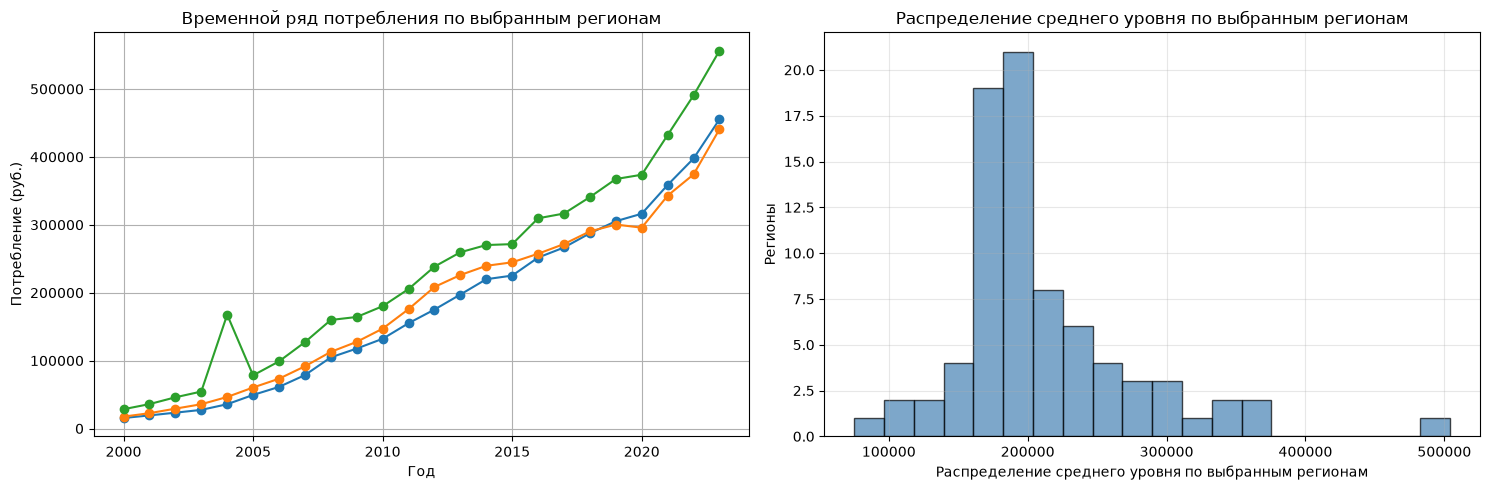

In [13]:
# Создаем отдельные временные ряды
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

time_series = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()


for region in regions_list:
    # Исходный ряд
    axes[0].plot(time_series[region], marker='o')
axes[0].set_title(f'Временной ряд потребления по выбранным регионам')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Потребление (руб.)')
axes[0].grid(True)

# справа - распределение среднего уровня по странам
mean_levels = [time_series[region].mean() for region in time_series.columns]
axes[1].hist(mean_levels, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
axes[1].set_title('Распределение среднего уровня по выбранным регионам')
axes[1].set_xlabel('Распределение среднего уровня по выбранным регионам')
axes[1].set_ylabel('Регионы')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:
# Рассчитываем показатели для каждого региона
def choosen_region_stats_make(df_long, regions_list):
    # Создаем временной ряд для каждого региона
    time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)
    # Рассчитываем показатели для каждого региона
    region_stats = []
    for region in regions_list:
        series = time_series[region].dropna()

        # Среднее значение
        mean_value = series.mean()

        # Подбор полинома второй степени
        coefficients = np.polyfit(series.index, series, 1)

        region_stats.append({
            'region_name': region,
            'Среднее значение': series.mean(),
            'Максимальное значение': series.max(),
            'Минималное значение': series.min(),
            'коэффициент наклона': coefficients[0],
            })
    region_stats = pd.DataFrame(region_stats)

    return region_stats

# Выводим результаты
choosen_region_stats = choosen_region_stats_make(df_long,regions_list)
show_markdown_table(choosen_region_stats, 'Статистика выбранных регионов')


### Статистика выбранных регионов

| region_name | Среднее значение | Максимальное значение | Минималное значение | коэффициент наклона |
| --- | --- | --- | --- | --- |
| Оренбургская область | 178194.083 | 455308.900 | 15462.500 | 18203.306 |
| Ставропольский край | 184669.137 | 440721.900 | 17488.300 | 17270.516 |
| Красноярский край | 232202.529 | 556338.000 | 28411.200 | 20211.434 |


**Критерии выбора:**
- Выбираем регионы  исходя из близости к центроидам.

**Базовые характеристики регионов приведены в таблице выше**
- Базовую статистику: среднее, минимум, максимум за период;
- оценку тренда — коэффициент наклона линейной регрессии через `np.polyfit`.

## Этап 4. Анализ выбранных регионов

Для каждого из трёх регионов выполним следующее:

1. Строим график исходного временного ряда (год — потребление).
2. Выделяем тренд по скользящим средним.
3. Проверим стационарность ряда с помощью теста Дики — Фуллера (`adfuller` из `statsmodels`).
---

### Анализ региона: Оренбургская область

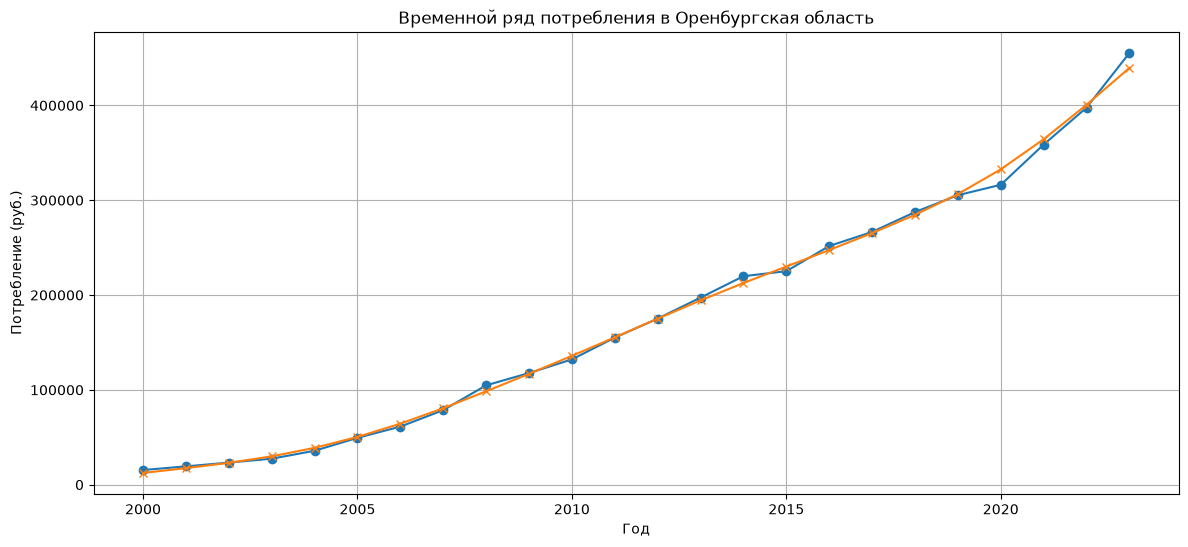

Статистика теста Дики-Фуллера: 2.142514955141867

p-значение: 0.9988317751235347

Ряд не стационарен.

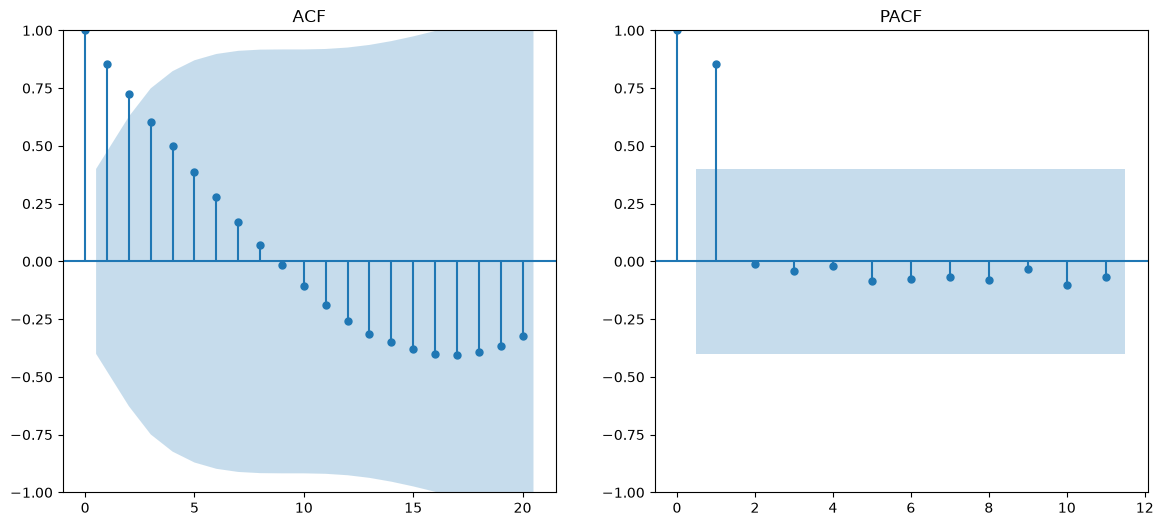

Среднее значение: 178,194.08

Стандартное отклонение: 130,690.56

Прирост за 2000–2023 гг.: 2844.60%

Среднегодовой прирост: 15.84%

### Анализ региона: Ставропольский край

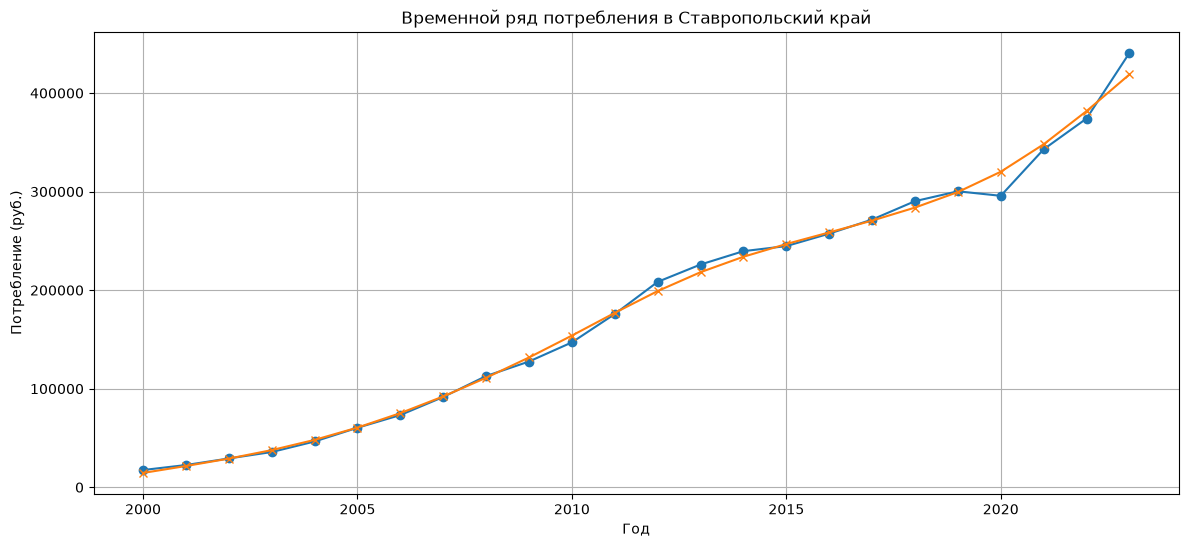

Статистика теста Дики-Фуллера: -0.765862203904777

p-значение: 0.8289447362964706

Ряд не стационарен.

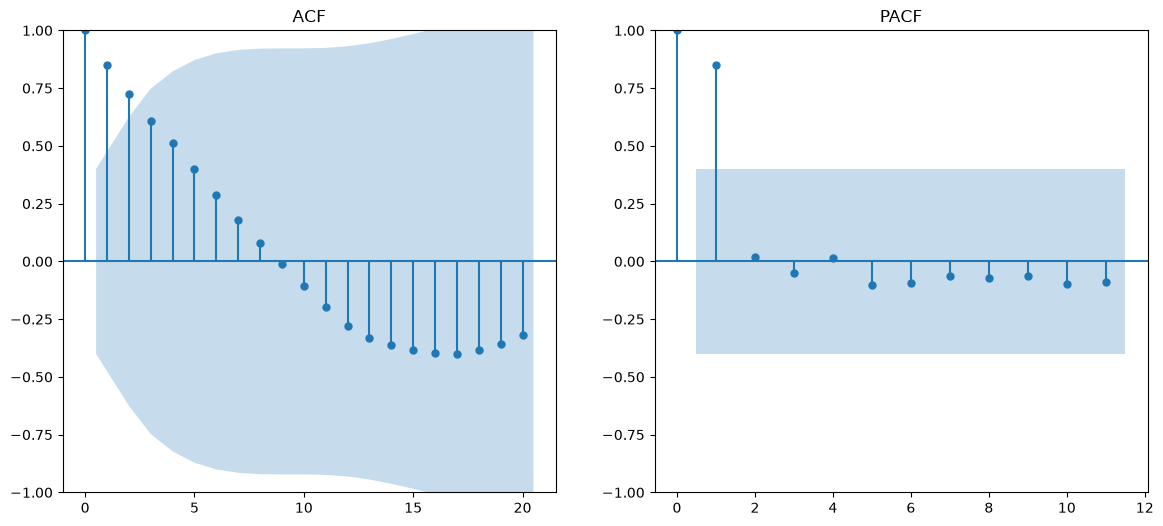

Среднее значение: 184,669.14

Стандартное отклонение: 123,577.04

Прирост за 2000–2023 гг.: 2420.10%

Среднегодовой прирост: 15.06%

### Анализ региона: Красноярский край

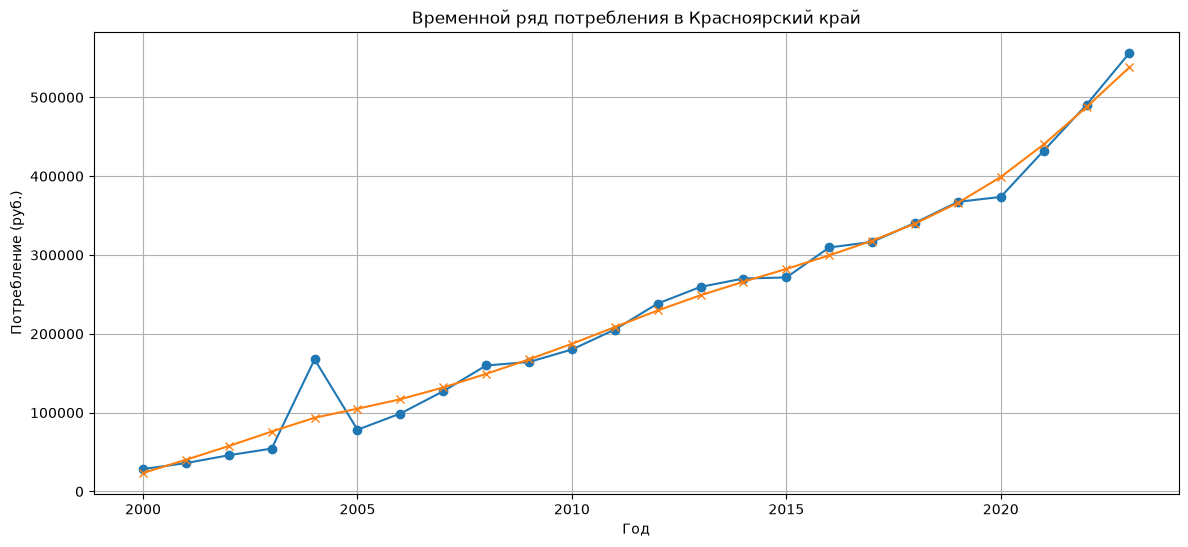

Статистика теста Дики-Фуллера: 0.8696216896148442

p-значение: 0.9926807947328817

Ряд не стационарен.

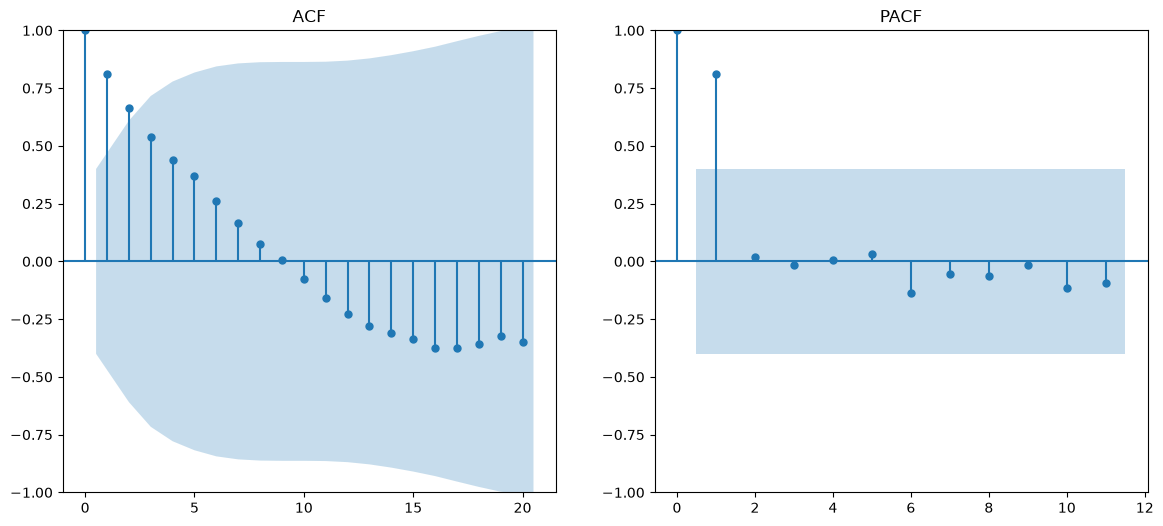

Среднее значение: 232,202.53

Стандартное отклонение: 146,722.90

Прирост за 2000–2023 гг.: 1858.16%

Среднегодовой прирост: 13.81%

In [15]:
# Создаем отдельные временные ряды
time_series = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()

def adf_test(series):
    """ADF-тест с подавлением FutureWarning (result_object=True)."""
    result = adfuller(series.dropna(), autolag='AIC',
                      regression='c', result_object=True)
    p_value = result.pvalue
    is_stationary = p_value < 0.05

    show_markdown(f"Статистика теста Дики-Фуллера: {result[0]}")
    show_markdown(f"p-значение: {result[1]}")

    if is_stationary:
         show_markdown('Ряд стационарен.')
    else:
        show_markdown('Ряд не стационарен.')
    return p_value, is_stationary

def hp_filter(series, lamb=6.25):
    """Фильтр Ходрика–Прескотта для годовых данных."""
    cycle, trend = sm.tsa.filters.hpfilter(series.values, lamb=lamb)
    return pd.Series(trend, index=series.index)

# Анализ каждого региона
for region in regions_list:
    show_markdown(f'### Анализ региона: {region}')
    # тренд
    hp_trend = hp_filter(time_series[region])
    # Исходный ряд
    plt.figure(figsize=(14, 6))
    plt.plot(time_series[region], marker='o')
    plt.plot(hp_trend, marker='x')
    plt.title(f'Временной ряд потребления в {region}')
    plt.xlabel('Год')
    plt.ylabel('Потребление (руб.)')
    plt.grid(True)
    plt.show()

    # Скользящее среднее для выявления тренда
    time_series[region + '_ma'] = time_series[region].rolling(window=3).mean()



    # Тест Дики-Фуллера на стационарность
    adf_test(time_series[region].dropna())


    # ACF требует лаг < n; для PACF используем лаг < n // 2.
    series = time_series[region].dropna()
    acf_lags = min(20, len(series) - 1)
    pacf_lags = min(20, len(series) // 2 - 1)

    plt.figure(figsize=(14, 6))
    plt.subplot(121)
    plot_acf(series, ax=plt.gca(), lags=acf_lags)
    plt.title('ACF')

    plt.subplot(122)
    plot_pacf(series, ax=plt.gca(), lags=pacf_lags)
    plt.title('PACF')
    plt.show()

    # Выводы
    show_markdown(f"Среднее значение: {time_series[region].mean():,.2f}")
    show_markdown(f"Стандартное отклонение: {time_series[region].std():,.2f}")
    total_growth = (series.iloc[-1] / series.iloc[0] - 1) * 100
    years = series.index[-1] - series.index[0]
    annual_growth = ((series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1) * 100
    show_markdown(f"Прирост за {series.index[0]}–{series.index[-1]} гг.: {total_growth:.2f}%")
    show_markdown(f"Среднегодовой прирост: {annual_growth:.2f}%")
    show_markdown("\n")


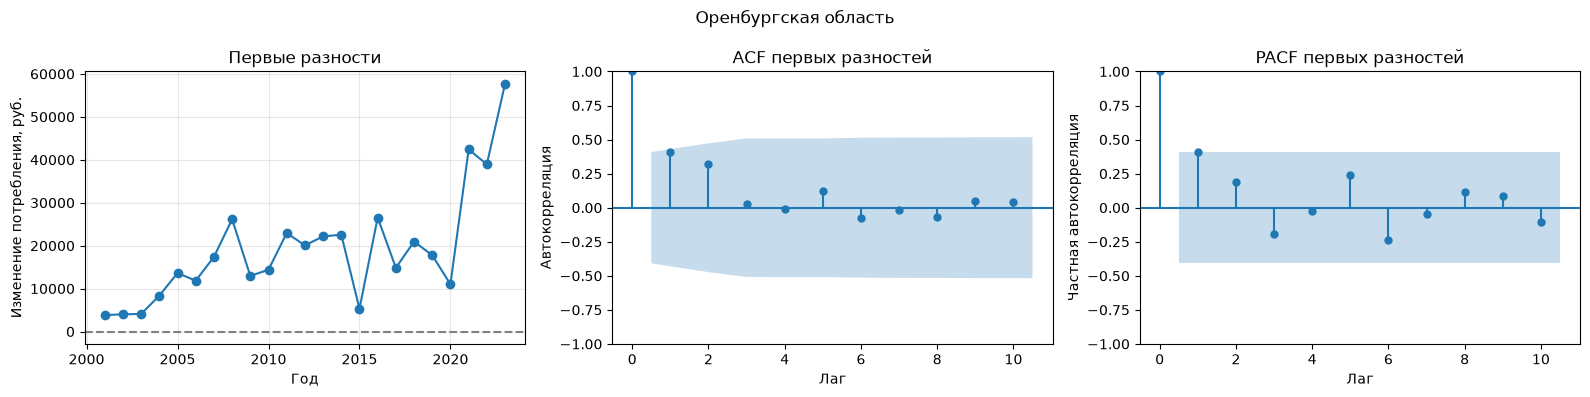

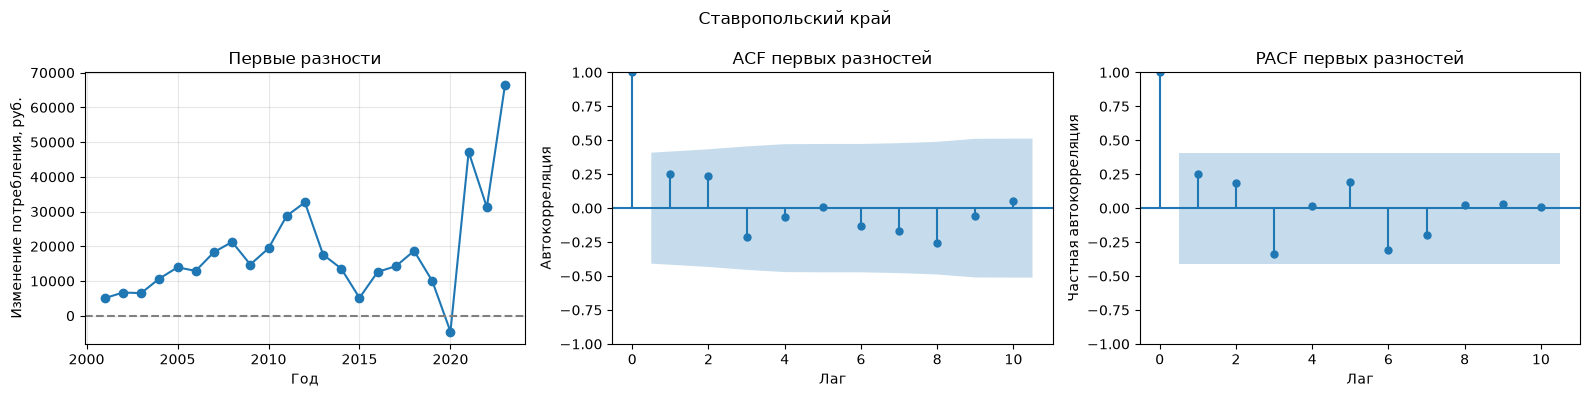

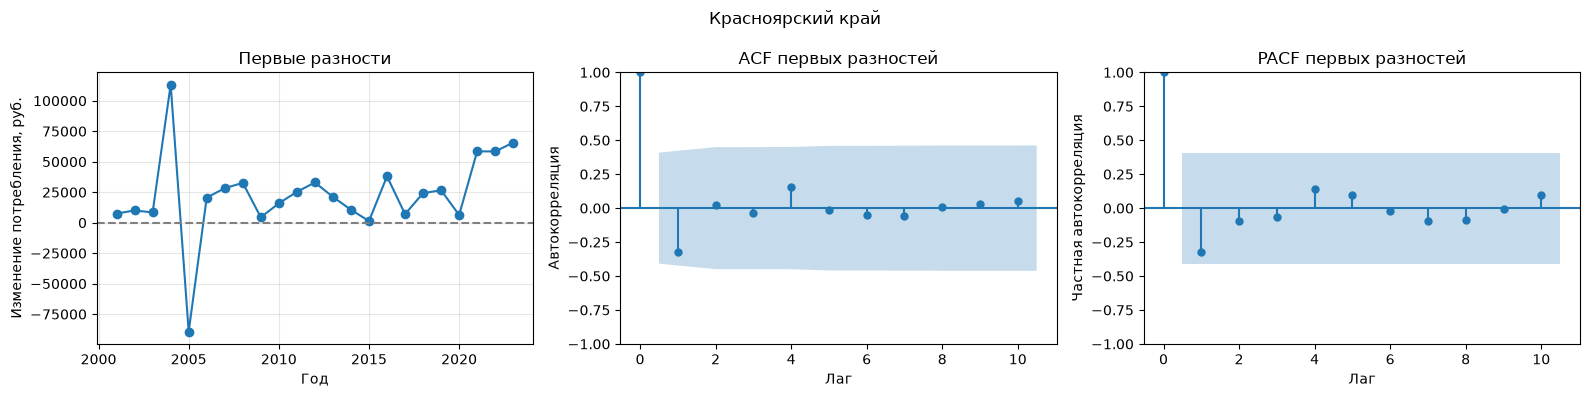

### ADF-тест до и после дифференцирования

| Регион | Преобразование | ADF | p-value | Вывод при α=0,05 |
| --- | --- | --- | --- | --- |
| Оренбургская область | Исходный ряд | 2.142515 | 0.998832 | Гипотеза единичного корня не отвергается |
| Оренбургская область | Первые разности | -1.090243 | 0.718947 | Гипотеза единичного корня не отвергается |
| Оренбургская область | Разности логарифмов | -3.335360 | 0.013370 | Гипотеза единичного корня отвергается |
| Ставропольский край | Исходный ряд | -0.765862 | 0.828945 | Гипотеза единичного корня не отвергается |
| Ставропольский край | Первые разности | -2.544998 | 0.104906 | Гипотеза единичного корня не отвергается |
| Ставропольский край | Разности логарифмов | -0.984715 | 0.758798 | Гипотеза единичного корня не отвергается |
| Красноярский край | Исходный ряд | 0.869622 | 0.992681 | Гипотеза единичного корня не отвергается |
| Красноярский край | Первые разности | 1.725302 | 0.998189 | Гипотеза единичного корня не отвергается |
| Красноярский край | Разности логарифмов | -7.366685 | 0.000000 | Гипотеза единичного корня отвергается |

In [16]:
adf_rows = []

for region in regions_list:
    original = time_series[region].dropna()
    differences = original.diff().dropna()

    # Проверяем исходный ряд и первые разности.
    for label, values in [
        ('Исходный ряд', original),
        ('Первые разности', original.diff().dropna()),
        ('Разности логарифмов', np.log(original).diff().dropna()),
    ]:
        result = adfuller(
            values,
            regression='c',
            autolag='AIC',
            result_object=True,
        )

        adf_rows.append({
            'Регион': region,
            'Преобразование': label,
            'ADF': result.statistic,
            'p-value': result.pvalue,
            'Вывод при α=0,05': (
                'Гипотеза единичного корня отвергается'
                if result.pvalue < 0.05
                else 'Гипотеза единичного корня не отвергается'
            ),
        })

    # После удаления тренда коррелограммы помогают выбирать p и q.
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    axes[0].plot(differences.index, differences, marker='o')
    axes[0].axhline(0, color='gray', linestyle='--')
    axes[0].set_title('Первые разности')
    axes[0].set_xlabel('Год')
    axes[0].set_ylabel('Изменение потребления, руб.')
    axes[0].grid(alpha=0.3)

    plot_acf(
        differences,
        lags=min(10, len(differences) - 1),
        ax=axes[1],
    )
    axes[1].set_title('ACF первых разностей')
    axes[1].set_xlabel('Лаг')
    axes[1].set_ylabel('Автокорреляция')

    plot_pacf(
        differences,
        lags=min(10, len(differences) // 2 - 1),
        ax=axes[2],
        method='ywm',
    )
    axes[2].set_title('PACF первых разностей')
    axes[2].set_xlabel('Лаг')
    axes[2].set_ylabel('Частная автокорреляция')

    fig.suptitle(region)
    plt.tight_layout()
    plt.show()

show_markdown_table(
    pd.DataFrame(adf_rows),
    'ADF-тест до и после дифференцирования',
    digits=6,
)

## Выводы

1. Ряды нестационарны, требуется дифференцирование. Обе коррелограммы постепенно затухают	Возможно сочетание AR и MA, например p=1, q=1.
2. Согласно тесту Дики — Фуллера, все три ряда получились нестационарными.
3. В целом все выбранные регионы следуют линии тренда. 
Сезонная декомпозиция не применялась, так как сам ряд не подразумевает сезонности.

## Этап 5. Прогнозирование

### Подготовка данных
- Мы делим данные на обучающую и тестовую выборки. Обучающая —  70% данных.
- Горизонт прогноза выбираем с 2016 года.

### Модели
Реализуем  три модели:
1. **NaiveForecaster** (`strategy="last"`) из `sktime` — бейзлайн.
2. **Модель экспоненциального сглаживания с трендом (Holt)** —  через `statsmodels.tsa.holtwinters.ExponentialSmoothing` (без сезонности, так как данные годовые).
3. **ARIMA** —  Параметры можно подбирать вручную на основе ACF/PACF или автоматически через `auto_arima` из `pmdarima`.

### Метрики
Для каждой модели используем на тестовой выборке следующие метрики:
- RMSE;
- MAPE.

### Оценка устойчивости прогноза

Реализуем **Expanding window forecast**: последовательно увеличивать обучающую выборку, сохраняя фиксированную тестовую, и смотреть, как меняется ошибка.

Применим выбранную стратегию к лучшей модели каждого региона и сравнить ошибки с фиксированным train/test. Сделать вывод об устойчивости прогноза.

### Визуализация
Построим графики:
- исторические данные;
- прогноз на тестовой выборке;
- прогноз на будущий период.
---

### Разбиение train/test

| Регион | Train: число точек | Train: годы | Test: число точек | Test: годы |
| --- | --- | --- | --- | --- |
| Оренбургская область | 17 | 2000–2016 | 7 | 2017–2023 |
| Ставропольский край | 17 | 2000–2016 | 7 | 2017–2023 |
| Красноярский край | 17 | 2000–2016 | 7 | 2017–2023 |

/home/alex/Yandex.Disk/mystuff/MIFI/time_row_exam/.venv/lib/python3.12/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/home/alex/Yandex.Disk/mystuff/MIFI/time_row_exam/.venv/lib/python3.12/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sk

### Оценка моделей на тестовой выборке

| Регион | Модель | Факт | Прогноз | RMSE | MAPE,% |
| --- | --- | --- | --- | --- | --- |
| Оренбургская область | Naive | 266559.600 | 251713.200 | 108711.240 | 23.888 |
| Оренбургская область | Holt | 266559.600 | 267795.304 | 34347.614 | 5.132 |
| Оренбургская область | ARIMA | 266559.600 | 271350.031 | 31605.143 | 5.051 |
| Ставропольский край | Naive | 271635.000 | 257365.200 | 91958.940 | 20.237 |
| Ставропольский край | Holt | 271635.000 | 269999.700 | 40403.376 | 6.866 |
| Ставропольский край | ARIMA | 271635.000 | 270872.317 | 34759.929 | 5.726 |
| Красноярский край | Naive | 316572.500 | 309547.200 | 129407.647 | 21.992 |
| Красноярский край | Holt | 316572.500 | 310404.822 | 70569.433 | 10.707 |
| Красноярский край | ARIMA | 316572.500 | 325731.599 | 58650.895 | 8.096 |

### Лучшая модель по каждому региону (по RMSE)

| Регион | Модель | RMSE | MAPE,% |
| --- | --- | --- | --- |
| Красноярский край | ARIMA | 58650.895 | 8.096 |
| Оренбургская область | ARIMA | 31605.143 | 5.051 |
| Ставропольский край | ARIMA | 34759.929 | 5.726 |

### Устойчивость прогноза (expanding window)

| Регион | Модель | Итерация | Год | Train_n | Прогноз | Факт | &#124;Ошибка&#124; | MAPE_1шаг,% |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Оренбургская область | ARIMA | 17 | 2017 | 17 | 271350.031 | 266559.600 | 4790.431 | 1.797 |
| Оренбургская область | ARIMA | 18 | 2018 | 18 | 289390.494 | 287510.400 | 1880.094 | 0.654 |
| Оренбургская область | ARIMA | 19 | 2019 | 19 | 307882.037 | 305274.800 | 2607.237 | 0.854 |
| Оренбургская область | ARIMA | 20 | 2020 | 20 | 323454.504 | 316281.600 | 7172.904 | 2.268 |
| Оренбургская область | ARIMA | 21 | 2021 | 21 | 331322.555 | 358689.300 | 27366.745 | 7.630 |
| Оренбургская область | ARIMA | 22 | 2022 | 22 | 373476.380 | 397631.200 | 24154.820 | 6.075 |
| Оренбургская область | ARIMA | 23 | 2023 | 23 | 429167.002 | 455308.900 | 26141.898 | 5.742 |
| Ставропольский край | ARIMA | 17 | 2017 | 17 | 270872.317 | 271635.000 | 762.683 | 0.281 |
| Ставропольский край | ARIMA | 18 | 2018 | 18 | 286127.357 | 290313.200 | 4185.843 | 1.442 |
| Ставропольский край | ARIMA | 19 | 2019 | 19 | 307595.694 | 300318.900 | 7276.794 | 2.423 |
| Ставропольский край | ARIMA | 20 | 2020 | 20 | 312305.820 | 295748.700 | 16557.120 | 5.598 |
| Ставропольский край | ARIMA | 21 | 2021 | 21 | 294240.864 | 342937.600 | 48696.736 | 14.200 |
| Ставропольский край | ARIMA | 22 | 2022 | 22 | 358435.186 | 374178.300 | 15743.114 | 4.207 |
| Ставропольский край | ARIMA | 23 | 2023 | 23 | 390391.482 | 440721.900 | 50330.418 | 11.420 |
| Красноярский край | ARIMA | 17 | 2017 | 17 | 325731.599 | 316572.500 | 9159.099 | 2.893 |
| Красноярский край | ARIMA | 18 | 2018 | 18 | 337431.671 | 340805.100 | 3373.429 | 0.990 |
| Красноярский край | ARIMA | 19 | 2019 | 19 | 351402.371 | 367377.700 | 15975.329 | 4.348 |
| Красноярский край | ARIMA | 20 | 2020 | 20 | 378379.000 | 373693.600 | 4685.400 | 1.254 |
| Красноярский край | ARIMA | 21 | 2021 | 21 | 393715.020 | 432207.100 | 38492.080 | 8.906 |
| Красноярский край | ARIMA | 22 | 2022 | 22 | 418203.787 | 490620.900 | 72417.113 | 14.760 |
| Красноярский край | ARIMA | 23 | 2023 | 23 | 458271.435 | 556338.000 | 98066.565 | 17.627 |

### Сравнение фиксированного test и expanding window

| Регион | Модель | RMSE_fixed | RMSE_expanding | Проверено лет | MAPE_fixed,% | MAPE_expanding(avg),% | Δ, п.п. |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Оренбургская область | ARIMA | 31605.143 | 17322.669 | 7 | 5.051 | 3.570 | -1.480 |
| Ставропольский край | ARIMA | 34759.929 | 28024.381 | 7 | 5.726 | 5.650 | -0.080 |
| Красноярский край | ARIMA | 58650.895 | 48866.236 | 7 | 8.096 | 7.250 | -0.850 |

**Интерпретация.** Expanding window использует обновление данных и прогноз на один год; фиксированный прогноз сделан сразу на весь test. Это разные режимы оценки. Лучшая модель выбрана по этому же test, поэтому сравнение носит описательный характер.

### Оренбургская область: весь ряд train + test

| Год | Факт | Выборка | Подгонка Naive | Прогноз Naive | Подгонка Holt | Прогноз Holt | Подгонка ARIMA | Прогноз ARIMA |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2000 | 15462.500 | train | — | — | 10403.292 | — | — | — |
| 2001 | 19291.600 | train | 15462.500 | — | 21055.597 | — | — | — |
| 2002 | 23314.600 | train | 19291.600 | — | 26121.905 | — | 23976.069 | — |
| 2003 | 27412.400 | train | 23314.600 | — | 29229.616 | — | 32812.093 | — |
| 2004 | 35774.400 | train | 27412.400 | — | 32245.549 | — | 31360.836 | — |
| 2005 | 49402.100 | train | 35774.400 | — | 40572.535 | — | 41011.478 | — |
| 2006 | 61248.300 | train | 49402.100 | — | 56485.650 | — | 57122.836 | — |
| 2007 | 78629.300 | train | 61248.300 | — | 71599.814 | — | 71799.552 | — |
| 2008 | 104772.500 | train | 78629.300 | — | 91374.252 | — | 92876.520 | — |
| 2009 | 117728.100 | train | 104772.500 | — | 121477.516 | — | 121852.729 | — |
| 2010 | 132127.000 | train | 117728.100 | — | 137839.992 | — | 135932.657 | — |
| 2011 | 155062.300 | train | 132127.000 | — | 150329.338 | — | 151954.949 | — |
| 2012 | 175140.900 | train | 155062.300 | — | 172255.120 | — | 171106.834 | — |
| 2013 | 197294.500 | train | 175140.900 | — | 194132.527 | — | 193097.513 | — |
| 2014 | 219858.600 | train | 197294.500 | — | 217581.197 | — | 219347.819 | — |
| 2015 | 225169.900 | train | 219858.600 | — | 241396.451 | — | 241106.711 | — |
| 2016 | 251713.200 | train | 225169.900 | — | 245082.573 | — | 242774.415 | — |
| 2017 | 266559.600 | test | — | 251713.200 | — | 267795.304 | — | 271350.031 |
| 2018 | 287510.400 | test | — | 251713.200 | — | 285825.796 | — | 285565.014 |
| 2019 | 305274.800 | test | — | 251713.200 | — | 303856.288 | — | 307097.240 |
| 2020 | 316281.600 | test | — | 251713.200 | — | 321886.780 | — | 325992.002 |
| 2021 | 358689.300 | test | — | 251713.200 | — | 339917.272 | — | 343204.535 |
| 2022 | 397631.200 | test | — | 251713.200 | — | 357947.764 | — | 362930.199 |
| 2023 | 455308.900 | test | — | 251713.200 | — | 375978.256 | — | 381661.687 |

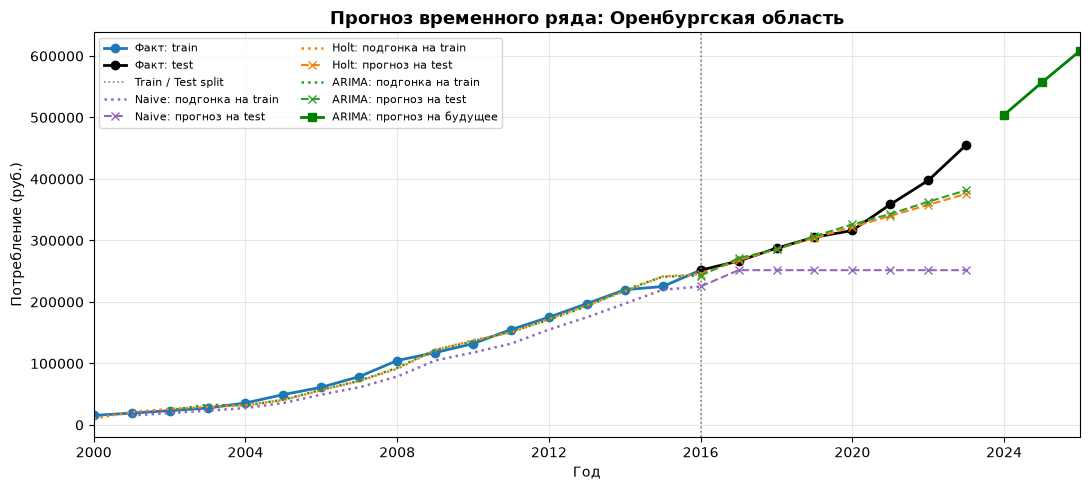

### Ставропольский край: весь ряд train + test

| Год | Факт | Выборка | Подгонка Naive | Прогноз Naive | Подгонка Holt | Прогноз Holt | Подгонка ARIMA | Прогноз ARIMA |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2000 | 17488.300 | train | — | — | 22295.752 | — | — | — |
| 2001 | 22553.800 | train | 17488.300 | — | 28588.645 | — | 33788.698 | — |
| 2002 | 29234.800 | train | 22553.800 | — | 27619.300 | — | 31653.313 | — |
| 2003 | 35751.500 | train | 29234.800 | — | 35915.800 | — | 39275.056 | — |
| 2004 | 46448.200 | train | 35751.500 | — | 42268.200 | — | 45696.080 | — |
| 2005 | 60378.100 | train | 46448.200 | — | 57144.900 | — | 58826.891 | — |
| 2006 | 73297.800 | train | 60378.100 | — | 74308.000 | — | 74639.558 | — |
| 2007 | 91609.500 | train | 73297.800 | — | 86217.500 | — | 86970.995 | — |
| 2008 | 112861.100 | train | 91609.500 | — | 109921.200 | — | 108422.582 | — |
| 2009 | 127607.300 | train | 112861.100 | — | 134112.700 | — | 131386.154 | — |
| 2010 | 147021.900 | train | 127607.300 | — | 142353.500 | — | 142344.109 | — |
| 2011 | 175800.000 | train | 147021.900 | — | 166436.500 | — | 164477.226 | — |
| 2012 | 208433.700 | train | 175800.000 | — | 204578.100 | — | 198707.909 | — |
| 2013 | 226036.000 | train | 208433.700 | — | 241067.400 | — | 233586.814 | — |
| 2014 | 239587.800 | train | 226036.000 | — | 243638.301 | — | 242435.982 | — |
| 2015 | 244730.700 | train | 239587.800 | — | 253139.600 | — | 253629.082 | — |
| 2016 | 257365.200 | train | 244730.700 | — | 249873.600 | — | 253875.285 | — |
| 2017 | 271635.000 | test | — | 257365.200 | — | 269999.700 | — | 270872.317 |
| 2018 | 290313.200 | test | — | 257365.200 | — | 282634.199 | — | 284887.579 |
| 2019 | 300318.900 | test | — | 257365.200 | — | 295268.699 | — | 299198.745 |
| 2020 | 295748.700 | test | — | 257365.200 | — | 307903.198 | — | 313682.223 |
| 2021 | 342937.600 | test | — | 257365.200 | — | 320537.698 | — | 328266.043 |
| 2022 | 374178.300 | test | — | 257365.200 | — | 333172.198 | — | 342908.294 |
| 2023 | 440721.900 | test | — | 257365.200 | — | 345806.697 | — | 357584.570 |

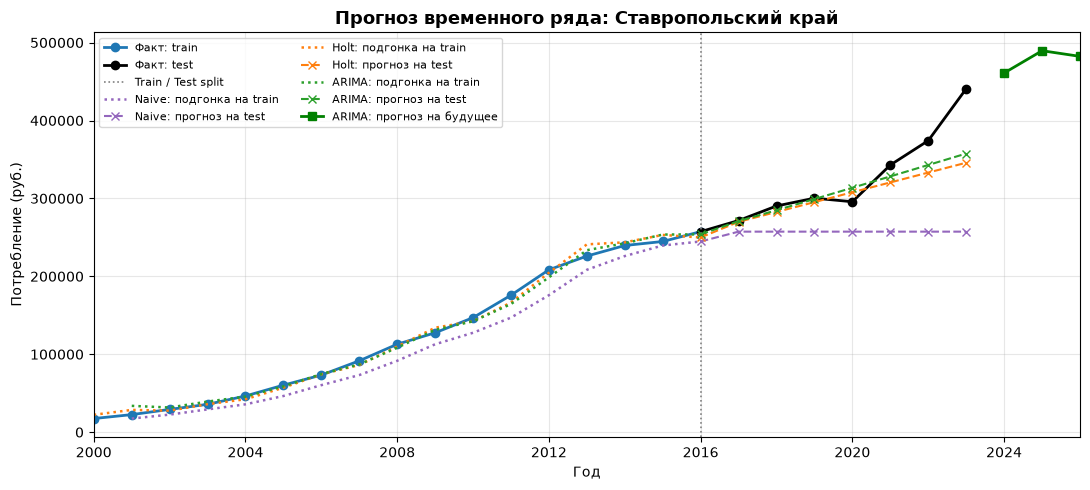

### Красноярский край: весь ряд train + test

| Год | Факт | Выборка | Подгонка Naive | Прогноз Naive | Подгонка Holt | Прогноз Holt | Подгонка ARIMA | Прогноз ARIMA |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2000 | 28411.200 | train | — | — | 27957.672 | — | — | — |
| 2001 | 35940.500 | train | 28411.200 | — | 44572.210 | — | 41099.495 | — |
| 2002 | 45949.300 | train | 35940.500 | — | 61186.748 | — | 57862.283 | — |
| 2003 | 54406.400 | train | 45949.300 | — | 77801.286 | — | 75447.261 | — |
| 2004 | 167593.200 | train | 54406.400 | — | 94415.824 | — | 93974.999 | — |
| 2005 | 78279.600 | train | 167593.200 | — | 111030.364 | — | 105181.495 | — |
| 2006 | 98845.700 | train | 78279.600 | — | 127644.902 | — | 129354.015 | — |
| 2007 | 127141.300 | train | 98845.700 | — | 144259.439 | — | 153313.813 | — |
| 2008 | 159827.700 | train | 127141.300 | — | 160873.977 | — | 187846.138 | — |
| 2009 | 164230.300 | train | 159827.700 | — | 177488.516 | — | 154460.614 | — |
| 2010 | 180098.800 | train | 164230.300 | — | 194103.054 | — | 178953.664 | — |
| 2011 | 205395.200 | train | 180098.800 | — | 210717.592 | — | 204251.977 | — |
| 2012 | 238380.700 | train | 205395.200 | — | 227332.130 | — | 225421.310 | — |
| 2013 | 259535.500 | train | 238380.700 | — | 243946.669 | — | 237517.015 | — |
| 2014 | 270163.800 | train | 259535.500 | — | 260561.207 | — | 259222.093 | — |
| 2015 | 271499.400 | train | 270163.800 | — | 277175.746 | — | 285755.341 | — |
| 2016 | 309547.200 | train | 271499.400 | — | 293790.284 | — | 310612.839 | — |
| 2017 | 316572.500 | test | — | 309547.200 | — | 310404.822 | — | 325731.599 |
| 2018 | 340805.100 | test | — | 309547.200 | — | 327019.361 | — | 338290.556 |
| 2019 | 367377.700 | test | — | 309547.200 | — | 343633.899 | — | 353451.671 |
| 2020 | 373693.600 | test | — | 309547.200 | — | 360248.437 | — | 380058.816 |
| 2021 | 432207.100 | test | — | 309547.200 | — | 376862.976 | — | 395254.890 |
| 2022 | 490620.900 | test | — | 309547.200 | — | 393477.514 | — | 411013.658 |
| 2023 | 556338.000 | test | — | 309547.200 | — | 410092.052 | — | 429641.310 |

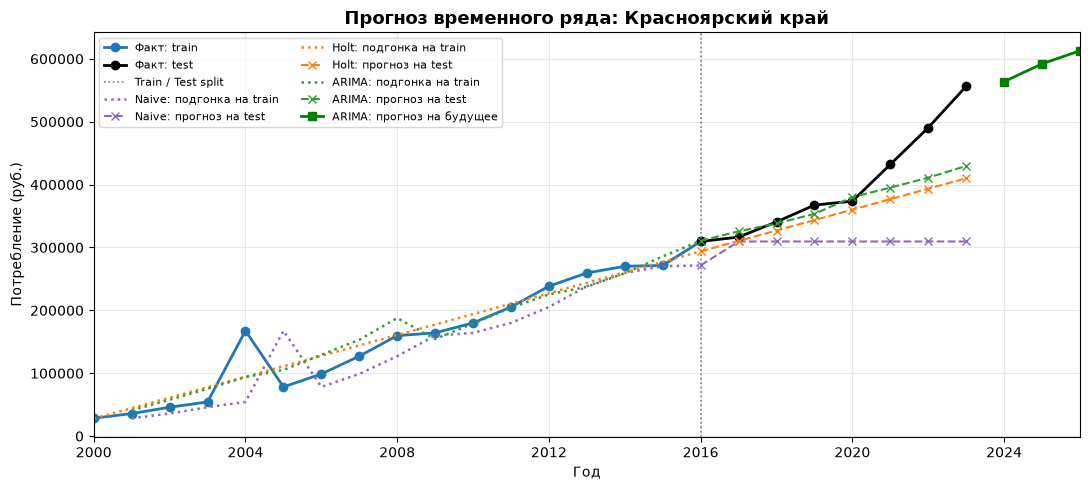

### Выводы

**Оренбургская область**: лучшая модель по RMSE — **ARIMA** (RMSE=31605.143, MAPE=5.05%). Статистическая модель превзошла бейзлайн.

**Ставропольский край**: лучшая модель по RMSE — **ARIMA** (RMSE=34759.929, MAPE=5.73%). Статистическая модель превзошла бейзлайн.

**Красноярский край**: лучшая модель по RMSE — **ARIMA** (RMSE=58650.895, MAPE=8.10%). Статистическая модель превзошла бейзлайн.

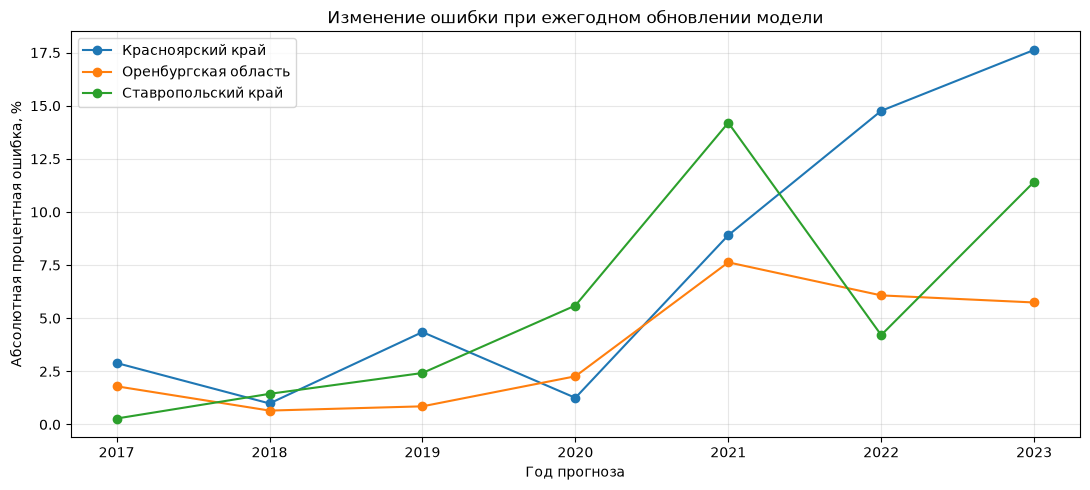

### Устойчивость: распределение абсолютной процентной ошибки, %

| Регион | Средняя | Медианная | Стандартное_отклонение | Максимальная |
| --- | --- | --- | --- | --- |
| Красноярский край | 7.254 | 4.348 | 6.700 | 17.627 |
| Оренбургская область | 3.574 | 2.268 | 2.834 | 7.630 |
| Ставропольский край | 5.653 | 4.207 | 5.251 | 14.200 |

In [17]:
if not regions_list or len(regions_list) != len(set(regions_list)):
    raise ValueError("Выберите неповторяющиеся регионы на этапе 3")
forecast_source = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()
missing_names = set(regions_list) - set(forecast_source.columns)
if missing_names:
    raise ValueError(f"Регионы отсутствуют в df_long: {sorted(missing_names)}")
forecast_regions = {}
for name in regions_list:
    series = forecast_source[name]
    series = series.copy().sort_index()
    if not isinstance(series.index, pd.DatetimeIndex):
        series.index = pd.to_datetime(series.index.astype(str), format="%Y")
    if series.index.has_duplicates:
        raise ValueError(f"{name}: повторяющиеся годы в индексе")
    series = series.asfreq("YS").astype(float)
    if not np.isfinite(series.to_numpy()).all():
        raise ValueError(f"{name}: ряд содержит пропуски или бесконечные значения")
    forecast_regions[name] = series
if not forecast_regions:
    raise ValueError("Нет выбранных регионов: выполните предыдущие ячейки")



# Train/test split + горизонт
# Общий горизонт сохраняет не менее 70% каждого ряда для обучения.
HORIZON = min(len(series) - int(np.ceil(0.7 * len(series)))
              for series in forecast_regions.values())
FUTURE_HORIZON = 3

splits = {}
split_rows = []
for name, s in forecast_regions.items():
    n = len(s)
    n_train = n - HORIZON
    train = s.iloc[:n_train].asfreq("YS")
    test  = s.iloc[n_train:].asfreq("YS")
    splits[name] = (train, test)
    split_rows.append({
        'Регион': name,
        'Train: число точек': len(train),
        'Train: годы': f'{train.index[0].year}–{train.index[-1].year}',
        'Test: число точек': len(test),
        'Test: годы': f'{test.index[0].year}–{test.index[-1].year}',
    })
show_markdown_table(pd.DataFrame(split_rows), 'Разбиение train/test')

# Наивный прогноз
def forecast_naive(train, horizon):
    """NaiveForecaster(strategy='last') — бейзлайн."""
    forecaster = NaiveForecaster(strategy="last")
    forecaster.set_config(remember_data=False)
    forecaster.fit(train)
    fh = ForecastingHorizon(np.arange(1, horizon + 1), is_relative=True)
    return forecaster.predict(fh)

# Холт
def forecast_holt(train, horizon):
    """Holt с аддитивным трендом, без сезонности."""
    model = ExponentialSmoothing(
        train, trend="add", seasonal=None, initialization_method="estimated"
    ).fit(optimized=True)
    return model.forecast(horizon)

# auto_arima
def fit_arima(train):
    """Подбираем порядок ARIMA только по обучающим данным."""
    return auto_arima(
        train, start_p=0, max_p=5, start_q=0, max_q=5,
        d=None, seasonal=False, trace=False,
        error_action='ignore', suppress_warnings=True, stepwise=True,
    )


def forecast_arima(train, horizon):
    """В pmdarima прогноз строится методом predict(n_periods=...)."""
    model = fit_arima(train)
    return model.predict(n_periods=horizon)


MODELS = {
    "Naive": forecast_naive,
    "Holt":  forecast_holt,
    "ARIMA": forecast_arima,
}


def fitted_on_train(train, model_name):
    """Подгонка на train; параметры Holt/ARIMA оценены по всему train."""
    if model_name == 'Naive':
        # Для первого года предыдущее наблюдение отсутствует.
        return train.shift(1)
    if model_name == 'Holt':
        fitted_model = ExponentialSmoothing(
            train, trend='add', seasonal=None, initialization_method='estimated'
        ).fit(optimized=True)
        return pd.Series(np.asarray(fitted_model.fittedvalues), index=train.index)
    if model_name == 'ARIMA':
        fitted_model = fit_arima(train)
        fitted = pd.Series(
            np.asarray(fitted_model.predict_in_sample()), index=train.index
        )
        # Пропускаем начальные значения с диффузной инициализацией.
        fitted.iloc[:max(1, fitted_model.arima_res_.loglikelihood_burn)] = np.nan
        return fitted


# Метрики
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if not mask.any():
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


# Оценка на фиксированном train/test
forecast_results = []
forecasts_test = {}   # для графиков

for name, (train, test) in splits.items():
    forecasts_test[name] = {}
    for mname, func in MODELS.items():
        try:
            pred = np.asarray(func(train, HORIZON), dtype=float)
            if pred.shape != (len(test),) or not np.isfinite(pred).all():
                raise ValueError("Прогноз должен содержать конечные значения для всех лет test")
            forecasts_test[name][mname] = pred
            forecast_results.append({
                "Регион":  name,
                "Модель":  mname,
                "Факт":    round(float(test.iloc[0]), 3) if len(test) else np.nan,
                "Прогноз": round(float(pred[0]), 3) if len(pred) else np.nan,
                "RMSE":    rmse(test.values, pred),
                "MAPE,%":  mape(test.values, pred),
            })
        except Exception as e:
            show_markdown(f"[{name}/{mname}] ошибка: {e}")

results_df = pd.DataFrame(forecast_results, columns=[
    "Регион", "Модель", "Факт", "Прогноз", "RMSE", "MAPE,%"
])
# Сравнение действительно только при успешной оценке всех трёх моделей.
expected_pairs = {(name, model) for name in forecast_regions for model in MODELS}
actual_pairs = set(zip(results_df["Регион"], results_df["Модель"]))
missing_pairs = expected_pairs - actual_pairs
if missing_pairs:
    raise RuntimeError(f"Не удалось оценить обязательные модели: {sorted(missing_pairs)}")
missing_regions = set(forecast_regions) - set(results_df["Регион"])
if missing_regions:
    raise RuntimeError(f"Не удалось оценить ни одну модель: {sorted(missing_regions)}")
show_markdown_table(results_df, 'Оценка моделей на тестовой выборке')


# 6. Устойчивость: Expanding window для лучшей модели региона
best_per_region = (results_df.dropna(subset=["RMSE"])
                   .sort_values("RMSE")
                   .groupby("Регион", as_index=False).first())

show_markdown_table(
    best_per_region[["Регион", "Модель", "RMSE", "MAPE,%"]],
    'Лучшая модель по каждому региону (по RMSE)',
)

stability_rows = []
for name, s in forecast_regions.items():
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    func = MODELS[best_name]

    # Expanding window: train на первых k точках, прогноз на (k+1)-ю
    for k in range(len(splits[name][0]), len(s)):
        train_k = s.iloc[:k].asfreq("YS")
        true_next = float(s.iloc[k])
        try:
            pred_val = float(np.asarray(func(train_k, 1), dtype=float)[0])
            if not np.isfinite(pred_val):
                raise ValueError("Одношаговый прогноз содержит неконечное значение")
            stability_rows.append({
                "Регион": name,
                "Модель": best_name,
                "Итерация": k,
                "Год": s.index[k].year,
                "Train_n": k,
                "Прогноз": pred_val,
                "Факт":   true_next,
                "|Ошибка|": abs(pred_val - true_next),
                "MAPE_1шаг,%": mape([true_next], [pred_val]),
            })
        except Exception as e:
            show_markdown(f"[{name}/{best_name}/iter{k}] ошибка: {e}")

stab_df = pd.DataFrame(stability_rows, columns=[
    "Регион", "Модель", "Итерация", "Год", "Train_n", "Прогноз", "Факт",
    "|Ошибка|", "MAPE_1шаг,%",
])
show_markdown_table(stab_df, 'Устойчивость прогноза (expanding window)')

# Сводка: фикс. train/test vs средняя по expanding window

cmp_rows = []
for name in forecast_regions:
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    fixed_mape = results_df[(results_df["Регион"] == name)
                            & (results_df["Модель"] == best_name)]["MAPE,%"].iloc[0]
    win = stab_df[stab_df["Регион"] == name]
    exp_mape = round(win["MAPE_1шаг,%"].mean(), 2) if len(win) else np.nan
    cmp_rows.append({
        "Регион": name, "Модель": best_name,
        "RMSE_fixed": best_per_region.loc[
            best_per_region["Регион"] == name, "RMSE"].iloc[0],
        "RMSE_expanding": rmse(win["Факт"], win["Прогноз"]) if len(win) else np.nan,
        "Проверено лет": len(win),
        "MAPE_fixed,%": fixed_mape,
        "MAPE_expanding(avg),%": exp_mape,
        "Δ, п.п.": round(exp_mape - fixed_mape, 2) if pd.notna(exp_mape) else np.nan,
    })
cmp_df = pd.DataFrame(cmp_rows)
show_markdown_table(cmp_df, 'Сравнение фиксированного test и expanding window')
display(Markdown(
    '**Интерпретация.** Expanding window использует обновление данных и прогноз на один год; '
    'фиксированный прогноз сделан сразу на весь test. Это разные режимы оценки. '
    'Лучшая модель выбрана по этому же test, поэтому сравнение носит описательный характер.'
))



# Визуализация: история + прогноз на тест + прогноз в будущее

forecasts_future = {}
full_series_tables = {}
fitted_train = {}
model_colors = {"Naive": "tab:purple", "Holt": "tab:orange", "ARIMA": "tab:green"}
for name, s in forecast_regions.items():
    train, test = splits[name]
    fig, ax = plt.subplots(figsize=(11, 5))

    # Подгонка по всему train служит визуализацией, метрики считаются на test.
    fitted_train[name] = {
        mname: fitted_on_train(train, mname)
        for mname in forecasts_test[name]
    }
    # Полный ряд, подгонка на train и отложенные прогнозы на test.
    full_table = pd.DataFrame({'Факт': s})
    full_table['Выборка'] = 'train'
    full_table.loc[test.index, 'Выборка'] = 'test'
    for mname, pred_arr in forecasts_test[name].items():
        full_table[f'Подгонка {mname}'] = fitted_train[name][mname]
        full_table[f'Прогноз {mname}'] = pd.Series(pred_arr, index=test.index)
    full_series_tables[name] = full_table
    markdown_table = full_table.copy()
    markdown_table.index = markdown_table.index.year
    show_markdown_table(
        markdown_table.rename_axis('Год'),
        f'{name}: весь ряд train + test', include_index=True,
    )

    # Весь исходный ряд; train и test выделены цветом.
    ax.plot(train.index, train.values, marker="o", lw=2,
            color="tab:blue", label="Факт: train")
    test_with_boundary = pd.concat([train.iloc[-1:], test])
    ax.plot(test_with_boundary.index, test_with_boundary.values, marker="o", lw=2,
            color="black", label="Факт: test")

    # Разделение train / test
    ax.axvline(x=train.index[-1], color="gray", ls=":", lw=1.2,
               label="Train / Test split")

    # Подгонка на train и прогноз на test одним цветом для каждой модели.
    for mname in MODELS:
        pred_arr = forecasts_test[name].get(mname)
        if pred_arr is None or len(test) == 0:
            continue
        pred_ser = pd.Series(pred_arr[:len(test)], index=test.index)
        train_fit = fitted_train[name][mname]
        ax.plot(train_fit.index, train_fit.values, ls=":", lw=1.8,
                color=model_colors[mname], label=f"{mname}: подгонка на train")
        # Соединяем последний fitted с первым прогнозом без разрыва линии.
        test_prediction = pd.concat([train_fit.iloc[-1:], pred_ser])
        ax.plot(test_prediction.index, test_prediction.values, marker="x", ls="--",
                color=model_colors[mname], label=f"{mname}: прогноз на test")

    # Прогноз в будущее — от лучшей модели, обученной на полном ряду
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    try:
        future_pred = np.asarray(
            MODELS[best_name](s.asfreq("YS"), FUTURE_HORIZON), dtype=float)
        future_idx = pd.date_range(
            s.index[-1] + pd.DateOffset(years=1),
            periods=FUTURE_HORIZON, freq="YS")
        if future_pred.shape != (FUTURE_HORIZON,) or not np.isfinite(future_pred).all():
            raise ValueError("Некорректный прогноз на будущий период")
        forecasts_future[name] = pd.Series(future_pred, index=future_idx, name=best_name)
        ax.plot(future_idx, future_pred, marker="s", ls="-", lw=2,
                color="green", label=f"{best_name}: прогноз на будущее")
    except Exception as e:
        show_markdown(f"[{name}] future forecast error: {e}")

    ax.set_title(f"Прогноз временного ряда: {name}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Год")
    ax.set_ylabel("Потребление (руб.)")
    ax.set_xlim(s.index[0], s.index[-1] + pd.DateOffset(years=FUTURE_HORIZON))
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8, ncol=2)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

# Выводы

display(Markdown('### Выводы'))
for name in forecast_regions:
    row = results_df[results_df["Регион"] == name].dropna(subset=["RMSE"])
    row = row.sort_values("RMSE")
    best = row.iloc[0]
    naive_rows = results_df[(results_df["Регион"] == name)
                            & (results_df["Модель"] == "Naive")]
    naive_rmse = naive_rows["RMSE"].iloc[0] if len(naive_rows) else np.nan
    better_than_naive = best["Модель"] != "Naive" and best["RMSE"] < naive_rmse
    msg = (f"**{name}**: лучшая модель по RMSE — **{best['Модель']}** "
           f"(RMSE={best['RMSE']:.3f}, MAPE={best['MAPE,%']:.2f}%). ")
    if pd.isna(naive_rmse):
        msg += "Бейзлайн не рассчитан: сравнение с ним недоступно."
    elif better_than_naive:
        msg += "Статистическая модель превзошла бейзлайн."
    else:
        msg += ("На выбранной тестовой выборке бейзлайн Naive не превзойдён.")
    display(Markdown(msg))


stability_summary = (
    stab_df.groupby('Регион')['MAPE_1шаг,%']
    .agg(
        Средняя='mean',
        Медианная='median',
        Стандартное_отклонение='std',
        Максимальная='max',
    )
)

fig, ax = plt.subplots(figsize=(11, 5))

for region, group in stab_df.groupby('Регион'):
    group = group.sort_values('Год')
    ax.plot(
        group['Год'],
        group['MAPE_1шаг,%'],
        marker='o',
        label=region,
    )

ax.set_title('Изменение ошибки при ежегодном обновлении модели')
ax.set_xlabel('Год прогноза')
ax.set_ylabel('Абсолютная процентная ошибка, %')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()



show_markdown_table(
    stability_summary,
    'Устойчивость: распределение абсолютной процентной ошибки, %',
    include_index=True,
)

## Этап 6. Анализ ошибок (5 баллов)

Для лучшей модели каждого региона:
1. Найдём точки с наибольшими ошибками (топ‑5 по абсолютной ошибке).
2. Представим результаты в виде таблицы или графика.
3. Сопоставим эти годы с известными экономическими событиями (кризис 2008, падение цен на нефть 2014, пандемия 2020, санкционное давление 2022).
4. Сформулируем гипотезы, почему модель ошиблась в эти периоды (например, структурные сдвиги, резкие изменения тренда, внешние шоки).

---

### Топ‑5 ошибок лучшей модели каждого региона

| Регион | Модель | Год | Факт | Прогноз | Ошибка | Абсолютная ошибка | Ошибка,% | Место |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Оренбургская область | ARIMA | 2023 | 455308.90 | 381661.69 | 73647.21 | 73647.21 | 16.18 | 1 |
| Оренбургская область | ARIMA | 2022 | 397631.20 | 362930.20 | 34701.00 | 34701.00 | 8.73 | 2 |
| Оренбургская область | ARIMA | 2021 | 358689.30 | 343204.54 | 15484.76 | 15484.76 | 4.32 | 3 |
| Оренбургская область | ARIMA | 2020 | 316281.60 | 325992.00 | -9710.40 | 9710.40 | 3.07 | 4 |
| Оренбургская область | ARIMA | 2017 | 266559.60 | 271350.03 | -4790.43 | 4790.43 | 1.80 | 5 |
| Ставропольский край | ARIMA | 2023 | 440721.90 | 357584.57 | 83137.33 | 83137.33 | 18.86 | 1 |
| Ставропольский край | ARIMA | 2022 | 374178.30 | 342908.29 | 31270.01 | 31270.01 | 8.36 | 2 |
| Ставропольский край | ARIMA | 2020 | 295748.70 | 313682.22 | -17933.52 | 17933.52 | 6.06 | 3 |
| Ставропольский край | ARIMA | 2021 | 342937.60 | 328266.04 | 14671.56 | 14671.56 | 4.28 | 4 |
| Ставропольский край | ARIMA | 2018 | 290313.20 | 284887.58 | 5425.62 | 5425.62 | 1.87 | 5 |
| Красноярский край | ARIMA | 2023 | 556338.00 | 429641.31 | 126696.69 | 126696.69 | 22.77 | 1 |
| Красноярский край | ARIMA | 2022 | 490620.90 | 411013.66 | 79607.24 | 79607.24 | 16.23 | 2 |
| Красноярский край | ARIMA | 2021 | 432207.10 | 395254.89 | 36952.21 | 36952.21 | 8.55 | 3 |
| Красноярский край | ARIMA | 2019 | 367377.70 | 353451.67 | 13926.03 | 13926.03 | 3.79 | 4 |
| Красноярский край | ARIMA | 2017 | 316572.50 | 325731.60 | -9159.10 | 9159.10 | 2.89 | 5 |

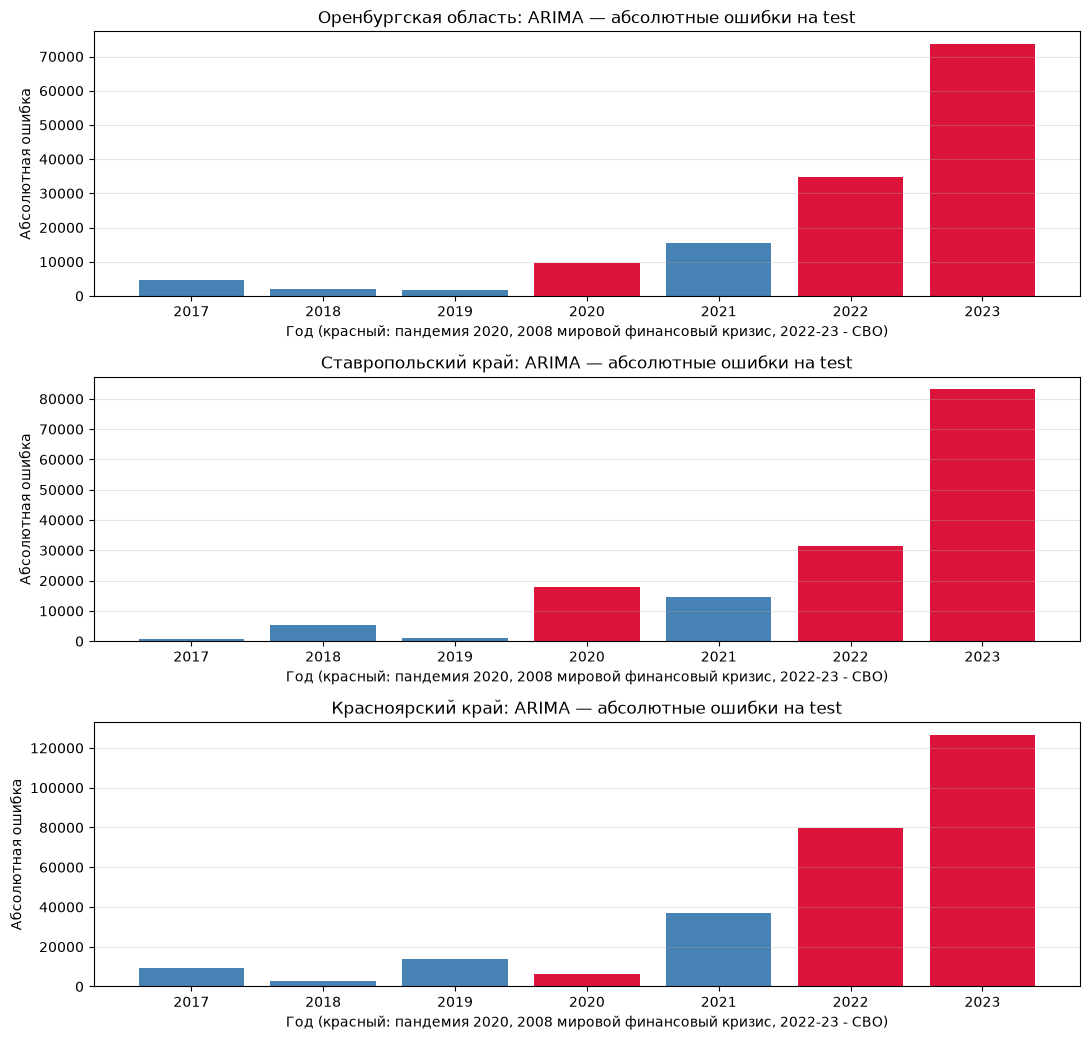

### Историческая диагностика: однолетние прогнозы

| Регион | Модель | Год | Событие | Обучение до | Факт | Прогноз на 1 год | Ошибка | Абсолютная ошибка | Ошибка,% |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Оренбургская область | ARIMA | 2008 | Начало мирового финансового кризиса | 2007 | 104772.50 | 94013.00 | 10759.50 | 10759.50 | 10.27 |
| Оренбургская область | ARIMA | 2009 | Спад после кризиса 2008 года | 2008 | 117728.10 | 128641.37 | -10913.27 | 10913.27 | 9.27 |
| Оренбургская область | ARIMA | 2020 | Пандемия COVID-19 и ограничения активности | 2019 | 316281.60 | 323454.50 | -7172.90 | 7172.90 | 2.27 |
| Ставропольский край | ARIMA | 2008 | Начало мирового финансового кризиса | 2007 | 112861.10 | 109707.80 | 3153.30 | 3153.30 | 2.79 |
| Ставропольский край | ARIMA | 2009 | Спад после кризиса 2008 года | 2008 | 127607.30 | 132742.69 | -5135.39 | 5135.39 | 4.02 |
| Ставропольский край | ARIMA | 2020 | Пандемия COVID-19 и ограничения активности | 2019 | 295748.70 | 312305.82 | -16557.12 | 16557.12 | 5.60 |
| Красноярский край | ARIMA | 2008 | Начало мирового финансового кризиса | 2007 | 159827.70 | 79570.90 | 80256.80 | 80256.80 | 50.21 |
| Красноярский край | ARIMA | 2009 | Спад после кризиса 2008 года | 2008 | 164230.30 | 88488.32 | 75741.98 | 75741.98 | 46.12 |
| Красноярский край | ARIMA | 2020 | Пандемия COVID-19 и ограничения активности | 2019 | 373693.60 | 378379.00 | -4685.40 | 4685.40 | 1.25 |


Оренбургская область: максимальная ошибка на test — 2023 год, 73647.21 (16.18%).

2020: место 4 из 7 по абсолютной ошибке, входит в топ‑5; прогноз переоценил показатель. Абсолютная ошибка — 9710.40.


Ставропольский край: максимальная ошибка на test — 2023 год, 83137.33 (18.86%).

2020: место 3 из 7 по абсолютной ошибке, входит в топ‑5; прогноз переоценил показатель. Абсолютная ошибка — 17933.52.


Красноярский край: максимальная ошибка на test — 2023 год, 126696.69 (22.77%).

2020: место 6 из 7 по абсолютной ошибке, не входит в топ‑5; прогноз переоценил показатель. Абсолютная ошибка — 6365.22.

In [18]:
# Ошибки сохранённого тестового прогноза: без повторного обучения.
error_frames = []
for name in forecast_regions:
    best_name = best_per_region.loc[
        best_per_region["Регион"].eq(name), "Модель"
    ].iloc[0]
    _, test = splits[name]
    pred = np.asarray(forecasts_test[name][best_name], dtype=float)
    if pred.shape != (len(test),):
        raise ValueError(f"{name}: длина прогноза не совпадает с test")
    errors = pd.DataFrame({
        "Регион": name, "Модель": best_name,
        "Год": test.index.year, "Факт": test.to_numpy(), "Прогноз": pred,
    })
    errors["Ошибка"] = errors["Факт"] - errors["Прогноз"]
    errors["Абсолютная ошибка"] = errors["Ошибка"].abs()
    errors["Ошибка,%"] = (
        errors["Абсолютная ошибка"] / errors["Факт"].abs().replace(0, np.nan) * 100
    )
    errors = errors.sort_values(
        ["Абсолютная ошибка", "Год"], ascending=[False, True]
    ).reset_index(drop=True)
    errors["Место"] = np.arange(1, len(errors) + 1)
    error_frames.append(errors)

errors_df = pd.concat(error_frames, ignore_index=True)
top5_errors_df = errors_df.loc[errors_df["Место"].le(5)].copy()
show_markdown_table(top5_errors_df, 'Топ‑5 ошибок лучшей модели каждого региона', digits=2)

fig, axes = plt.subplots(
    len(forecast_regions), 1, figsize=(11, 3.5 * len(forecast_regions)), squeeze=False
)
for ax, (name, group) in zip(axes[:, 0], errors_df.groupby("Регион", sort=False)):
    group = group.sort_values("Год")
    colors = ["crimson" if year in [2008,2020,2022,2023] else "steelblue" for year in group["Год"]]
    ax.bar(group["Год"], group["Абсолютная ошибка"], color=colors)
    ax.set_title(f"{name}: {group['Модель'].iloc[0]} — абсолютные ошибки на test")
    ax.set_xticks(group["Год"])
    ax.set_ylabel("Абсолютная ошибка")
    ax.set_xlabel("Год (красный: пандемия 2020, 2008 мировой финансовый кризис, 2022-23 - СВО)")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

# Сопоставление событий при одинаковом однолетнем горизонте.
event_labels = {
    2008: "Начало мирового финансового кризиса",
    2009: "Спад после кризиса 2008 года",
    2020: "Пандемия COVID-19 и ограничения активности",
}
event_rows = []
for name, series in forecast_regions.items():
    best_name = best_per_region.loc[
        best_per_region["Регион"].eq(name), "Модель"
    ].iloc[0]
    for year, event in event_labels.items():
        date = pd.Timestamp(year=year, month=1, day=1)
        history = series.loc[series.index < date]
        if date not in series.index or len(history) < 4:
            continue
        actual = float(series.loc[date])
        prediction = float(np.asarray(MODELS[best_name](history, 1))[0])
        if not np.isfinite(prediction):
            raise ValueError(f"{name}, {year}: некорректный прогноз")
        event_rows.append({
            "Регион": name, "Модель": best_name, "Год": year,
            "Событие": event, "Обучение до": history.index[-1].year,
            "Факт": actual, "Прогноз на 1 год": prediction,
            "Ошибка": actual - prediction,
            "Абсолютная ошибка": abs(actual - prediction),
            "Ошибка,%": mape([actual], [prediction]),
        })
event_errors_df = pd.DataFrame(event_rows)
show_markdown_table(event_errors_df, 'Историческая диагностика: однолетние прогнозы', digits=2)

for name, group in errors_df.groupby("Регион", sort=False):
    worst = group.loc[group["Место"].eq(1)].iloc[0]
    show_markdown(f"\n{name}: максимальная ошибка на test — {int(worst['Год'])} год, "
          f"{worst['Абсолютная ошибка']:.2f} ({worst['Ошибка,%']:.2f}%).")
    pandemic = group.loc[group["Год"].eq(2020)]
    if not pandemic.empty:
        row = pandemic.iloc[0]
        position = int(row["Место"])
        inclusion = "входит" if position <= 5 else "не входит"
        direction = "недооценил" if row["Ошибка"] > 0 else "переоценил" if row["Ошибка"] < 0 else "точно предсказал"
        show_markdown(f"2020: место {position} из {len(group)} по абсолютной ошибке, "
              f"{inclusion} в топ‑5; прогноз {direction} показатель. "
              f"Абсолютная ошибка — {row['Абсолютная ошибка']:.2f}.")


## Вывод
Модели обучаются на данных за предыдущие годы и шоковые события, такие как ковид или санкции, предсказать не могут.

## Этап 7. Индивидуальные рекомендации (4 балла)

Оренбургская область:
• Учитывая прогнозируемый рост потребления с ~450 000 руб. (2022 г.) до ~600 000 руб. (2026 г.), предусмотреть в бюджете 2024–2026 гг. увеличение ассигнований на развитие  инфраструктуры .
• С учётом сопоставимой точности Holt и ARIMA, использовать ансамбль прогнозов (среднее Holt + ARIMA) как базовый сценарий бюджетного планирования; порог корректировки — отклонение факта от ансамбля >8%. 

Ставропольский край:
екомендации:
• Учитывая ускорение роста после 2020 г. (+~80% за 6 лет), предусмотреть в бюджете 2024–2026 гг. увеличение ассигнований на развитие логистической инфраструктуры в горных и отдалённых районах не менее чем на 50% относительно уровня 2022 г.
• С учётом сопоставимой точности Holt и ARIMA, использовать ансамбль прогнозов (среднее Holt + ARIMA) как базовый сценарий планирования; порог корректировки — отклонение факта от ансамбля >10%.

Красноярский край:
Рекомендации:
• Учитывая резкий рост в 2020–2022 гг. (+~31%) и прогнозируемое продолжение тренда, предусмотреть в бюджете 2024–2026 гг. увеличение ассигнований на развитие транспортной и складской инфраструктуры не менее чем на 60% относительно уровня 2022 г.
• С учётом сопоставимой точности Holt и ARIMA, использовать ансамбль прогнозов (среднее Holt + ARIMA) как базовый сценарий планирования; порог корректировки — отклонение факта от ансамбля >10%.


In [19]:
display(Markdown('## Этап 8. Выводы по проекту '))

display(Markdown('1. Выделены три  кластера '))

show_markdown_table(region_stats.groupby('Кластер')[
        ['Среднее значение',
         'Коэфф. вариации',
         'Среднегодовой темп роста',
         'Макс. падение',
         'Доля отрицат. динамики']
    ].mean().round(3), 'Характеристики кластеров', include_index=True)

display(Markdown('2. К ним подобраны три региона'))
show_markdown_table(choosen_region_stats, 'Статистика выбранных регионов')
display(Markdown('3. Модели ARIMA и Holt показали близкие значения , но ARIMA оказалась чуть лучше. Строгая статистическая обоснованность: ARIMA опирается на формальные критерии стационарности, автокорреляции и частной автокорреляции (ACF/PACF), что позволяет обоснованно выбирать порядок модели (p,d,q) и проверять значимость коэффициентов; Holt использует эвристическую настройку сглаживающих параметров (α, β) без формальных тестов значимости.'))
display(Markdown('4. Модели не могу надежно предсказывать шоковые события типа ковида.'))
display(Markdown('5. Для улочшения прогнозирования можно использовать анасамбли или использовать модель с внешними призанакми типа SARIMAX.'))

## Этап 8. Выводы по проекту 

1. Выделены три  кластера 

### Характеристики кластеров

| Кластер | Среднее значение | Коэфф. вариации | Среднегодовой темп роста | Макс. падение | Доля отрицат. динамики |
| --- | --- | --- | --- | --- | --- |
| 0 | 200429.906 | 73.025 | 15.753 | 2.656 | 0.001 |
| 1 | 238637.892 | 66.537 | 14.994 | -2.290 | 0.041 |
| 2 | 232202.529 | 63.187 | 13.807 | -53.292 | 0.043 |

2. К ним подобраны три региона

### Статистика выбранных регионов

| region_name | Среднее значение | Максимальное значение | Минималное значение | коэффициент наклона |
| --- | --- | --- | --- | --- |
| Оренбургская область | 178194.083 | 455308.900 | 15462.500 | 18203.306 |
| Ставропольский край | 184669.137 | 440721.900 | 17488.300 | 17270.516 |
| Красноярский край | 232202.529 | 556338.000 | 28411.200 | 20211.434 |

3. Модели ARIMA и Holt показали близкие значения , но ARIMA оказалась чуть лучше. Строгая статистическая обоснованность: ARIMA опирается на формальные критерии стационарности, автокорреляции и частной автокорреляции (ACF/PACF), что позволяет обоснованно выбирать порядок модели (p,d,q) и проверять значимость коэффициентов; Holt использует эвристическую настройку сглаживающих параметров (α, β) без формальных тестов значимости.

4. Модели не могу надежно предсказывать шоковые события типа ковида.

5. Для улочшения прогнозирования можно использовать анасамбли или использовать модель с внешними призанакми типа SARIMAX.